<div align="center">

# Bonificación · Demostraciones de Deep Learning

### Deep Learning aplicado a ingeniería

**Universidad del Norte** · Profesor: Dr. Lihki Rubio
**Autor:** Juan David Díaz Fernández · Noviembre de 2026

</div>

---

## Contenido

Cada sección copia el enunciado tal como aparece en las lecciones, lo resuelve de forma
completa y lo **verifica numéricamente** dentro del propio cuaderno. Las demostraciones usan
la notación de la lección correspondiente.

| N.º | Resultado a demostrar | Lección | Qué se entrega |
|:---:|:----------------------|:-------:|:---------------|
| **1** | Ejercicio: cinco iteraciones de gradiente descendente sobre la red del ejemplo | 2 · §2.7 | Tabla, gráfica y respuesta a las tres preguntas |
| **2** | Derivada de la sigmoidea logística: $f'(z)=a\,f(z)\,(1-f(z))$ | 2 · §2.9 | Demostración y verificación |
| **3** | Longitud de paso del gradiente descendente con error cuadrático medio: $0<\mu<2/\lambda_{\max}$ | 2 · §2.1 | Demostración (condición necesaria y suficiente) y verificación |
| **4** | Proposición 3.1: gradientes de una capa convolucional | 3 | Demostración y verificación |
| **5** | Teorema 3.3: retropropagación (regla de la cadena en modo inverso) | 3 | Demostración, conteo de costo y verificación |
| **6** | Lema 3.1: campo receptivo | 3 | Demostración y verificación sobre 500 arquitecturas |
| **7** | Teorema 3.4: beneficio de la profundidad | 3 | Demostración de los tres incisos y verificación |

**Cómo leer una sección.** *Enunciado* (copiado de la lección) → *Demostración* (cada paso
justificado) → *Verificación numérica* (el cuaderno comprueba el resultado con un cálculo
independiente) → *Conclusión*. El símbolo $\blacksquare$ marca el final de una demostración
y ✔ una comprobación numérica superada. Al final hay una tabla con todas las comprobaciones.

**Requisitos.** Python 3 con `numpy`, `pandas` y `matplotlib` (`scipy` es opcional y solo se usa
como contraste adicional en la sección 4). Todas las celdas son deterministas (semillas fijas).

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

try:
    from scipy import signal as _sig          # solo para un contraste adicional (sección 4)
except Exception:
    _sig = None

# ---- estilo de las gráficas -------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.7,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.labelsize": 10.5,
    "legend.frameon": False, "font.size": 10.5,
})
C = dict(azul="#2F5D9B", naranja="#D9822B", verde="#3E8E5A",
         rojo="#B8433A", gris="#6B7280", morado="#7A5BA6", cian="#2A9DA6")

# ---- utilidades -------------------------------------------------------------
def tabla(df, decimales=6, index=False):
    """Muestra un DataFrame con un número fijo de decimales."""
    fmt = {c: (lambda v, d=decimales: f"{v:.{d}f}") for c in df.select_dtypes(include=["float"]).columns}
    display(HTML(df.to_html(formatters=fmt, index=index, border=0, justify="center")))

VERIF = []   # registro global de comprobaciones numéricas
def registrar(seccion, comprobacion, error, tol):
    """Registra una comprobación y falla ruidosamente si el error supera la tolerancia."""
    ok = bool(error <= tol)
    VERIF.append(dict(seccion=seccion, comprobacion=comprobacion, error=float(error), tolerancia=float(tol), ok=ok))
    print(("✔" if ok else "✘"), f"{comprobacion}  |  error = {error:.2e}  (tolerancia {tol:.1e})")
    assert ok, f"Falla la comprobación: {comprobacion}"

def dif_central(f, x, h=1e-6):
    """Gradiente por diferencias finitas centrales de f: R^n -> R."""
    x = np.asarray(x, dtype=float); g = np.zeros_like(x)
    for i in range(x.size):
        e = np.zeros_like(x); e.flat[i] = h
        g.flat[i] = (f(x + e) - f(x - e)) / (2 * h)
    return g
print("Entorno listo.")

Entorno listo.


---
# 1 · Ejercicio de la §2.7: cinco iteraciones de gradiente descendente

*Fuente: Lección 2 (Multilayer Perceptron), §2.7 «Entrenamiento de MLP», figuras 2.15–2.18.*

### Enunciado

> **Ejercicio para el estudiante: iteraciones de gradiente descendente**
>
> Complete a mano, o con una calculadora o una hoja de cálculo, **cinco iteraciones** de gradiente descendente sobre la red del ejemplo, con tasa de aprendizaje $\alpha=0.01$ y la función de pérdida $L=(y-\hat y)^2$. Parta de los pesos iniciales del ejemplo desarrollado. El objetivo es observar que el error disminuye a medida que se actualizan los pesos.
>
> En cada iteración $t=1,\dots,5$ debe realizar los siguientes pasos:
> 1. Calcular el paso hacia adelante con los pesos vigentes para obtener $p_1,\dots,p_{10}$ y $\hat y^{(t)}$.
> 2. Calcular la pérdida $L^{(t)}=(y-\hat y^{(t)})^2$.
> 3. Calcular los seis gradientes $\partial L/\partial\omega_j$, con $j=1,\dots,6$, mediante la regla de la cadena.
> 4. Actualizar los seis pesos con $\omega_j^{(t+1)}=\omega_j^{(t)}-\alpha\,\partial L/\partial\omega_j$.
>
> Registre sus resultados en una tabla como la siguiente:
>
> | Iteración $t$ | $\omega_1$ | $\omega_2$ | $\omega_3$ | $\omega_4$ | $\omega_5$ | $\omega_6$ | $\hat y^{(t)}$ | $L^{(t)}$ |
> |:--:|:--:|:--:|:--:|:--:|:--:|:--:|:--:|:--:|
> | 0 … 5 | | | | | | | | |
>
> Responda las siguientes preguntas:
> 1. Grafique $L^{(t)}$ en función de $t$. ¿Disminuye la pérdida en cada iteración?
> 2. ¿Por qué los cambios en los pesos son pequeños con $\alpha=0.01$? ¿Qué esperaría observar con un valor mayor de $\alpha$?
> 3. ¿Cuántas iteraciones adicionales cree que se necesitarían para que la pérdida cambie menos que una tolerancia de $10^{-6}$? Justifique su respuesta.
>
> Conserve al menos cuatro cifras decimales en todos los cálculos, para que la reducción del error sea apreciable.

### 1.1 Planteamiento: la red del ejemplo

La lección usa una red con dos entradas, una capa oculta de dos neuronas sigmoideas y salida lineal
(Fig. 2.15). Su grafo computacional (Fig. 2.16) fija las ecuaciones del paso hacia adelante, con
entradas $y_1=-1$, $y_2=2$, valor objetivo $y=1$ y $\sigma(z)=1/(1+e^{-z})$:

$$
\begin{aligned}
p_1&=y_1\omega_1, & p_2&=y_2\omega_2, & p_5&=p_1+p_2, & p_7&=\sigma(p_5), & p_9&=\omega_5\,p_7,\\
p_3&=y_1\omega_3, & p_4&=y_2\omega_4, & p_6&=p_3+p_4, & p_8&=\sigma(p_6), & p_{10}&=\omega_6\,p_8,
\end{aligned}
\qquad \hat y=p_9+p_{10},\qquad L=(y-\hat y)^2 .
$$

Los **pesos iniciales** del ejemplo desarrollado son
$\omega_1=-0.33,\ \omega_2=-0.33,\ \omega_3=0.57,\ \omega_4=-0.01,\ \omega_5=0.07,\ \omega_6=0.82$.

**Paso hacia atrás (regla de la cadena, Fig. 2.17).** Cada gradiente es el producto de las derivadas
parciales a lo largo del camino que une la pérdida con el peso:

$$
\frac{\partial L}{\partial \hat y}=-2(y-\hat y),\qquad \frac{\partial \hat y}{\partial p_9}=\frac{\partial \hat y}{\partial p_{10}}=1,\qquad
\frac{\partial p_7}{\partial p_5}=\sigma'(p_5)=p_7^2e^{-p_5},\qquad \frac{\partial p_8}{\partial p_6}=p_8^2e^{-p_6},
$$

$$
\begin{aligned}
\frac{\partial L}{\partial\omega_5}&=-2(y-\hat y)\,p_7, &
\frac{\partial L}{\partial\omega_1}&=-2(y-\hat y)\,\omega_5\,p_7^2e^{-p_5}\,y_1, &
\frac{\partial L}{\partial\omega_2}&=-2(y-\hat y)\,\omega_5\,p_7^2e^{-p_5}\,y_2,\\
\frac{\partial L}{\partial\omega_6}&=-2(y-\hat y)\,p_8, &
\frac{\partial L}{\partial\omega_3}&=-2(y-\hat y)\,\omega_6\,p_8^2e^{-p_6}\,y_1, &
\frac{\partial L}{\partial\omega_4}&=-2(y-\hat y)\,\omega_6\,p_8^2e^{-p_6}\,y_2 .
\end{aligned}
$$

(La igualdad $\sigma'(p)=p_7^2e^{-p}$ se demuestra en la sección 2; con $y_1=-1$ y $y_2=2$ se obtienen los
factores $\times(-1)$ y $\times 2$ que aparecen en la lección.)

**Convención de la tabla.** La fila $t$ contiene los pesos $\omega^{(t)}$ obtenidos tras $t$
actualizaciones y los valores $\hat y^{(t)}$ y $L^{(t)}$ que produce esa red. La fila $0$ corresponde a los pesos
iniciales. Cada paso $t-1\to t$ ejecuta los cuatro pasos del enunciado (adelante, pérdida, seis gradientes,
actualización); en total son **cinco iteraciones** y la fila 5 muestra el resultado final.

In [2]:
# ---- Datos del ejemplo (Lección 2, Fig. 2.16 y 2.18) ------------------------
y_in  = np.array([-1.0, 2.0])      # entradas [y1, y2]
y_obj = 1.0                        # valor objetivo y
w0    = np.array([-0.33, -0.33, 0.57, -0.01, 0.07, 0.82])   # ω1..ω6 iniciales
alpha = 0.01                       # tasa de aprendizaje

def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))

def adelante(w):
    """Paso hacia adelante sobre el grafo de la Fig. 2.16. Devuelve (p, ŷ, L) con p[1..10]."""
    w1, w2, w3, w4, w5, w6 = w
    p = {}
    p[1] = y_in[0] * w1; p[2] = y_in[1] * w2; p[5] = p[1] + p[2]; p[7] = sigmoide(p[5]); p[9]  = w5 * p[7]
    p[3] = y_in[0] * w3; p[4] = y_in[1] * w4; p[6] = p[3] + p[4]; p[8] = sigmoide(p[6]); p[10] = w6 * p[8]
    yhat = p[9] + p[10]
    return p, yhat, (y_obj - yhat) ** 2

def gradientes(w):
    """Los seis gradientes ∂L/∂ωj por regla de la cadena (Fig. 2.17). Devuelve (g, ∂L/∂ŷ)."""
    w1, w2, w3, w4, w5, w6 = w
    p, yhat, L = adelante(w)
    dL_dyhat = -2.0 * (y_obj - yhat)                 # ∂L/∂ŷ
    ds5 = p[7] ** 2 * np.exp(-p[5])                  # ∂p7/∂p5 = σ'(p5)
    ds6 = p[8] ** 2 * np.exp(-p[6])                  # ∂p8/∂p6 = σ'(p6)
    g = np.array([dL_dyhat * w5 * ds5 * y_in[0],     # ∂L/∂ω1
                  dL_dyhat * w5 * ds5 * y_in[1],     # ∂L/∂ω2
                  dL_dyhat * w6 * ds6 * y_in[0],     # ∂L/∂ω3
                  dL_dyhat * w6 * ds6 * y_in[1],     # ∂L/∂ω4
                  dL_dyhat * p[7],                   # ∂L/∂ω5
                  dL_dyhat * p[8]])                  # ∂L/∂ω6
    return g, dL_dyhat

def perdida(w):
    return adelante(w)[2]

### 1.2 Comprobación del punto de partida contra la Fig. 2.18

Antes de iterar conviene verificar que nuestro código reproduce los valores que la lección muestra en azul
(paso hacia adelante con los pesos iniciales). La lección redondea a tres decimales.

In [3]:
p, yhat, L = adelante(w0)
leccion = {1: 0.33, 2: -0.66, 3: -0.57, 4: -0.02, 5: -0.33, 6: -0.59, 7: 0.418, 8: 0.357, 9: 0.029, 10: 0.293}
filas = [(f"p{i}", leccion[i], p[i], abs(leccion[i] - p[i])) for i in range(1, 11)]
filas += [("ŷ", 0.322, yhat, abs(0.322 - yhat)), ("L", 0.459, L, abs(0.459 - L))]
df = pd.DataFrame(filas, columns=["variable", "lección (Fig. 2.18)", "recalculado", "diferencia"])
tabla(df, 4)
# Las diferencias (≤ 1.1e-3) vienen de que la lección encadena valores ya redondeados (p10 = 0.357·0.82, L = (1 − 0.322)²).
registrar("1", "Paso hacia adelante coincide con la Fig. 2.18 (tolerancia de redondeo)", df["diferencia"].max(), 1.5e-3)
print(f"\nNota: (1 - 0.322)^2 = {(1-0.322)**2:.4f}  (valor de la lección)   frente a   (1 - ŷ)^2 = {L:.4f}  (con ŷ sin redondear).")

✔ Paso hacia adelante coincide con la Fig. 2.18 (tolerancia de redondeo)  |  error = 1.07e-03  (tolerancia 1.5e-03)

Nota: (1 - 0.322)^2 = 0.4597  (valor de la lección)   frente a   (1 - ŷ)^2 = 0.4601  (con ŷ sin redondear).


variable,lección (Fig. 2.18),recalculado,diferencia
p1,0.3300,0.3300,0.0000
p2,-0.6600,-0.6600,0.0000
p3,-0.5700,-0.5700,0.0000
p4,-0.0200,-0.0200,0.0000
p5,-0.3300,-0.3300,0.0000
p6,-0.5900,-0.5900,0.0000
p7,0.4180,0.4182,0.0002
p8,0.3570,0.3566,0.0004
p9,0.0290,0.0293,0.0003
p10,0.2930,0.2924,0.0006


### 1.3 Verificación de los gradientes (y una discrepancia en la figura de la lección)

Antes de actualizar pesos comprobamos los seis gradientes de dos formas independientes: **diferencias finitas
centrales** sobre $L(\omega)$ y los valores que imprime la lección. La lección da
$\partial L/\partial\omega_5=-0.384,\ \partial L/\partial\omega_6=-0.328,\ \partial L/\partial\omega_1=0.016,\ \partial L/\partial\omega_2=-0.032,\ \partial L/\partial\omega_3=0.173,\ \partial L/\partial\omega_4=-0.346$.

In [4]:
g, dL_dyhat = gradientes(w0)
g_fd = dif_central(perdida, w0)                       # diferencias finitas (independientes de la regla de la cadena)
g_leccion = np.array([0.016, -0.032, 0.173, -0.346, -0.384, -0.328])   # valores impresos en la lección (ω1..ω6)

df = pd.DataFrame({"peso": [f"ω{j}" for j in range(1, 7)],
                   "regla de la cadena": g, "diferencias finitas": g_fd,
                   "lección": g_leccion, "lección / nuestro": g_leccion / g})
tabla(df, 4)
registrar("1", "Gradientes por regla de la cadena = diferencias finitas centrales", np.abs(g - g_fd).max(), 1e-8)

print(f"\n∂L/∂ŷ = -2(y-ŷ) = {dL_dyhat:.4f}      ← valor correcto con ŷ = {yhat:.4f} y y = 1")
print(f"La Fig. 2.18 de la lección muestra -0.919, que coincide con -2L = {-2*(1-0.322)**2:.3f} (es decir, -2(y-ŷ)^2) y no con -2(y-ŷ).")
print(f"Razón lección/nuestro (constante en los seis pesos): {np.round(g_leccion/g, 3)}  ≈  y-ŷ = {1-yhat:.3f}")

✔ Gradientes por regla de la cadena = diferencias finitas centrales  |  error = 4.30e-11  (tolerancia 1.0e-08)

∂L/∂ŷ = -2(y-ŷ) = -1.3566      ← valor correcto con ŷ = 0.3217 y y = 1
La Fig. 2.18 de la lección muestra -0.919, que coincide con -2L = -0.919 (es decir, -2(y-ŷ)^2) y no con -2(y-ŷ).
Razón lección/nuestro (constante en los seis pesos): [0.692 0.692 0.678 0.678 0.677 0.678]  ≈  y-ŷ = 0.678


peso,regla de la cadena,diferencias finitas,lección,lección / nuestro
ω1,0.0231,0.0231,0.0160,0.6925
ω2,-0.0462,-0.0462,-0.0320,0.6925
ω3,0.2552,0.2552,0.1730,0.6778
ω4,-0.5105,-0.5105,-0.3460,0.6778
ω5,-0.5674,-0.5674,-0.3840,0.6768
ω6,-0.4838,-0.4838,-0.3280,0.6780


**Observación.** Los seis gradientes que calculamos coinciden con las diferencias finitas (error del orden de
$10^{-11}$), así que la regla de la cadena está bien aplicada. Los valores impresos en la lección son menores por un
factor común $\approx 0.68\approx y-\hat y$: la figura 2.18 usa $\partial L/\partial\hat y=-0.919$, que es $-2L$ (con $L=0.459$) en
lugar de $-2(y-\hat y)=-1.357$. Como $L=(y-\hat y)^2$, su derivada es $-2(y-\hat y)$ y no $-2L$. Por eso **en este ejercicio usamos
el gradiente correcto**, verificado numéricamente. Más abajo se compara el primer paso con el que se obtendría usando los
números impresos en la lección.

### 1.4 Las cinco iteraciones

In [5]:
N_IT = 5
W = [w0.copy()]; YH = []; LL = []; G = [None]; P = []
w = w0.copy()
for t in range(N_IT + 1):
    p_t, yh_t, L_t = adelante(w)        # pasos 1 y 2: paso hacia adelante y pérdida con los pesos vigentes
    P.append(p_t); YH.append(yh_t); LL.append(L_t)
    if t == N_IT:
        break
    g_t, _ = gradientes(w)              # paso 3: seis gradientes por regla de la cadena
    w = w - alpha * g_t                 # paso 4: actualización ω ← ω − α ∂L/∂ω
    W.append(w.copy()); G.append(g_t)
W = np.array(W); YH = np.array(YH); LL = np.array(LL)

tabla_principal = pd.DataFrame({"Iteración t": range(N_IT + 1),
                                **{f"ω{j+1}": W[:, j] for j in range(6)},
                                "ŷ(t)": YH, "L(t)": LL})
print("Tabla solicitada (6 decimales):")
tabla(tabla_principal, 6)

Tabla solicitada (6 decimales):


Iteración t,ω1,ω2,ω3,ω4,ω5,ω6,ŷ(t),L(t)
0,-0.330000,-0.330000,0.570000,-0.010000,0.070000,0.820000,0.321717,0.460067
1,-0.330231,-0.329538,0.567448,-0.004895,0.075674,0.824838,0.328257,0.451239
2,-0.330478,-0.329043,0.564896,0.000208,0.081296,0.829669,0.334813,0.442473
3,-0.330742,-0.328517,0.562345,0.005310,0.086868,0.834491,0.341387,0.433771
4,-0.331020,-0.327959,0.559796,0.010408,0.092389,0.839305,0.347977,0.425134
5,-0.331314,-0.327373,0.557249,0.015502,0.097860,0.844110,0.354582,0.416565


**Pasos intermedios de cada iteración** (para poder revisar el cálculo a mano): los seis gradientes que se usan para pasar de $t-1$ a $t$
y los valores $p_1,\dots,p_{10}$ del paso hacia adelante en cada fila.

In [6]:
print("Gradientes ∂L/∂ωj usados en cada iteración (la fila t actualiza ω(t-1) → ω(t)):")
tabla(pd.DataFrame({"Iteración t": range(1, N_IT + 1), **{f"∂L/∂ω{j+1}": [G[t][j] for t in range(1, N_IT + 1)] for j in range(6)}}), 6)
print("\nValores del paso hacia adelante p1…p10 con los pesos de cada fila:")
tabla(pd.DataFrame({"t": range(N_IT + 1), **{f"p{i}": [P[t][i] for t in range(N_IT + 1)] for i in range(1, 11)}}), 6)

Gradientes ∂L/∂ωj usados en cada iteración (la fila t actualiza ω(t-1) → ω(t)):

Valores del paso hacia adelante p1…p10 con los pesos de cada fila:


Iteración t,∂L/∂ω1,∂L/∂ω2,∂L/∂ω3,∂L/∂ω4,∂L/∂ω5,∂L/∂ω6
1,0.023105,-0.046210,0.255232,-0.510465,-0.567371,-0.483798
2,0.024742,-0.049483,0.255186,-0.510371,-0.562278,-0.483075
3,0.026326,-0.052652,0.255078,-0.510155,-0.557191,-0.482276
4,0.027858,-0.055716,0.254908,-0.509816,-0.552106,-0.481399
5,0.029339,-0.058678,0.254675,-0.509351,-0.547025,-0.480443


t,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10
0,0.330000,-0.660000,-0.570000,-0.020000,-0.330000,-0.590000,0.418241,0.356635,0.029277,0.292441
1,0.330231,-0.659076,-0.567448,-0.009791,-0.328845,-0.577238,0.418522,0.359568,0.031671,0.296586
2,0.330478,-0.658086,-0.564896,0.000417,-0.327608,-0.564479,0.418823,0.362512,0.034049,0.300765
3,0.330742,-0.657033,-0.562345,0.010620,-0.326291,-0.551725,0.419143,0.365464,0.036410,0.304977
4,0.331020,-0.655919,-0.559796,0.020816,-0.324898,-0.538980,0.419482,0.368425,0.038756,0.309221
5,0.331314,-0.654745,-0.557249,0.031003,-0.323432,-0.526246,0.419840,0.371393,0.041085,0.313496


### 1.5 Verificación independiente de las cinco iteraciones

Recalculamos la trayectoria completa con una **implementación distinta** (forma matricial, sin el grafo de nodos $p_i$) y comparamos
pesos, $\hat y$ y $L$ en cada iteración. También comprobamos el gradiente de cada iteración con diferencias finitas.

In [7]:
def paso_matricial(w):
    """Misma red en forma matricial: z = y_in·W1, h = σ(z), ŷ = h·v. Devuelve (ŷ, L, gradiente de ω1..ω6)."""
    W1 = np.array([[w[0], w[2]],      # fila: entrada y1 → (g1 con ω1, g2 con ω3)
                   [w[1], w[3]]])     # fila: entrada y2 → (g1 con ω2, g2 con ω4)
    v = np.array([w[4], w[5]])
    h = sigmoide(y_in @ W1)           # (2,) salidas de las neuronas ocultas g1, g2
    yh = h @ v                        # salida lineal
    dyh = -2.0 * (y_obj - yh)
    dv = dyh * h
    dz = dyh * v * h * (1.0 - h)      # usa σ' = σ(1-σ)
    dW1 = np.outer(y_in, dz)          # (2×2)
    return yh, (y_obj - yh) ** 2, np.array([dW1[0, 0], dW1[1, 0], dW1[0, 1], dW1[1, 1], dv[0], dv[1]])

w = w0.copy(); err_w = err_y = err_L = err_g = err_fd = 0.0
for t in range(N_IT + 1):
    yh_m, L_m, g_m = paso_matricial(w)
    err_w = max(err_w, np.abs(w - W[t]).max()); err_y = max(err_y, abs(yh_m - YH[t])); err_L = max(err_L, abs(L_m - LL[t]))
    if t < N_IT:
        err_g  = max(err_g,  np.abs(g_m - G[t + 1]).max())
        err_fd = max(err_fd, np.abs(dif_central(perdida, w) - G[t + 1]).max())
        w = w - alpha * g_m
registrar("1", "Pesos de las 5 iteraciones: grafo de nodos vs forma matricial", err_w, 1e-12)
registrar("1", "ŷ(t) y L(t): grafo de nodos vs forma matricial", max(err_y, err_L), 1e-12)
registrar("1", "Gradientes de las 5 iteraciones: cadena vs matricial", err_g, 1e-12)
registrar("1", "Gradientes de las 5 iteraciones: cadena vs diferencias finitas", err_fd, 1e-8)

✔ Pesos de las 5 iteraciones: grafo de nodos vs forma matricial  |  error = 1.11e-16  (tolerancia 1.0e-12)
✔ ŷ(t) y L(t): grafo de nodos vs forma matricial  |  error = 1.67e-16  (tolerancia 1.0e-12)
✔ Gradientes de las 5 iteraciones: cadena vs matricial  |  error = 2.22e-16  (tolerancia 1.0e-12)
✔ Gradientes de las 5 iteraciones: cadena vs diferencias finitas  |  error = 1.19e-10  (tolerancia 1.0e-08)


### 1.6 Comparación con el primer paso que resulta de los números de la lección

La lección ejecuta solo la actualización de $\omega_5$ ($0.07-0.01\times(-0.384)=0.0738$) y dice que «el resto se actualizan con la misma fórmula».
Si se aplicara esa fórmula con los gradientes impresos en la figura, el primer paso sería el de la columna central; la columna derecha es el
paso con el gradiente correcto (el que usamos).

In [8]:
w_lec = w0 - alpha * g_leccion          # primer paso usando los gradientes impresos en la lección
comp = pd.DataFrame({"peso": [f"ω{j}" for j in range(1, 7)], "ω(0)": w0,
                     "ω(1) con gradientes de la lección": w_lec, "ω(1) con gradiente correcto (usado aquí)": W[1],
                     "diferencia": np.abs(w_lec - W[1])})
tabla(comp, 5)

peso,ω(0),ω(1) con gradientes de la lección,ω(1) con gradiente correcto (usado aquí),diferencia
ω1,-0.33000,-0.33016,-0.33023,0.00007
ω2,-0.33000,-0.32968,-0.32954,0.00014
ω3,0.57000,0.56827,0.56745,0.00082
ω4,-0.01000,-0.00654,-0.00490,0.00164
ω5,0.07000,0.07384,0.07567,0.00183
ω6,0.82000,0.82328,0.82484,0.00156


### 1.7 Pregunta 1 — Gráfica de $L^{(t)}$ y comprobación de que disminuye en cada iteración

Para $\alpha$ pequeña, un paso de gradiente cambia la pérdida, a primer orden, en
$\Delta L\approx-\alpha\,\|\nabla L\|^2<0$ (desarrollo de Taylor de primer orden: $L(\omega-\alpha\nabla L)=L(\omega)-\alpha\|\nabla L\|^2+O(\alpha^2)$).
Mientras el gradiente no se anule, esto es **negativo**, de modo que la pérdida baja. Lo comprobamos con los números.

¿Disminuye la pérdida en cada iteración? → True

Reducción total en 5 iteraciones: 0.460067 → 0.416565  (−0.043503, 9.46 %)
✔ ΔL real vs predicción de primer orden −α‖∇L‖² (error relativo máx.)  |  error = 1.99e-03  (tolerancia 5.0e-02)


iteración t,L(t-1),L(t),ΔL real,−α‖∇L‖² (1er orden),reducción acumulada
1,0.460067,0.451239,-0.008828,-0.008844,0.008828
2,0.451239,0.442473,-0.008766,-0.008782,0.017594
3,0.442473,0.433771,-0.008702,-0.008718,0.026296
4,0.433771,0.425134,-0.008637,-0.008653,0.034933
5,0.425134,0.416565,-0.008570,-0.008587,0.043503


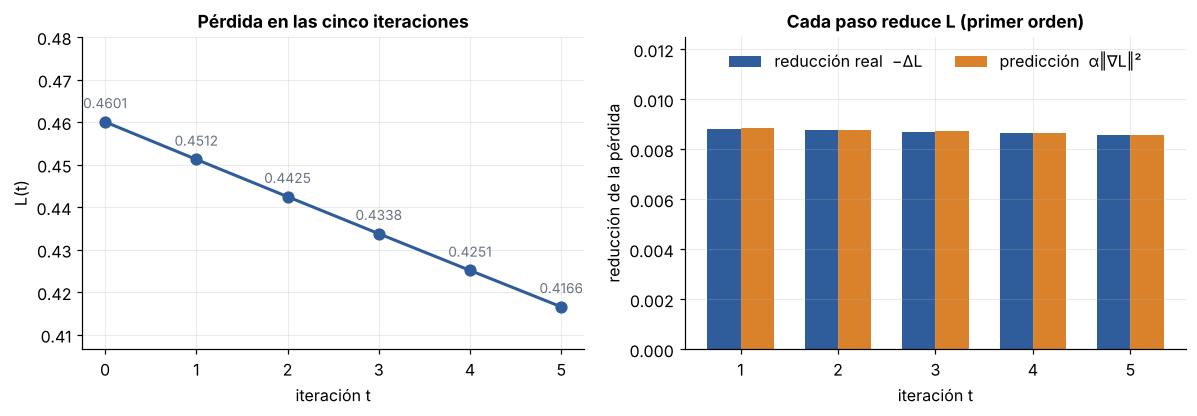

In [9]:
dL_real = np.diff(LL)                                                      # ΔL(t) = L(t) − L(t−1)
dL_pred = np.array([-alpha * np.sum(G[t] ** 2) for t in range(1, N_IT + 1)])   # predicción de primer orden −α‖∇L‖²
print("¿Disminuye la pérdida en cada iteración? →", bool(np.all(dL_real < 0)))
tabla(pd.DataFrame({"iteración t": range(1, N_IT + 1), "L(t-1)": LL[:-1], "L(t)": LL[1:],
                    "ΔL real": dL_real, "−α‖∇L‖² (1er orden)": dL_pred,
                    "reducción acumulada": LL[0] - LL[1:]}), 6)
print(f"\nReducción total en 5 iteraciones: {LL[0]:.6f} → {LL[-1]:.6f}  (−{LL[0]-LL[-1]:.6f}, {100*(LL[0]-LL[-1])/LL[0]:.2f} %)")
registrar("1", "ΔL real vs predicción de primer orden −α‖∇L‖² (error relativo máx.)", np.max(np.abs(dL_real - dL_pred) / np.abs(dL_real)), 5e-2)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
ax[0].plot(range(N_IT + 1), LL, "o-", color=C["azul"], lw=2, ms=7)
for t in range(N_IT + 1):
    ax[0].annotate(f"{LL[t]:.4f}", (t, LL[t]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color=C["gris"])
ax[0].set(xlabel="iteración t", ylabel="L(t)", title="Pérdida en las cinco iteraciones", xticks=range(N_IT + 1))
ax[0].set_ylim(LL[-1] - 0.01, LL[0] + 0.02)
ax[1].bar(np.arange(1, N_IT + 1) - 0.17, -dL_real, 0.34, color=C["azul"], label="reducción real  −ΔL")
ax[1].bar(np.arange(1, N_IT + 1) + 0.17, -dL_pred, 0.34, color=C["naranja"], label="predicción  α‖∇L‖²")
ax[1].set(xlabel="iteración t", ylabel="reducción de la pérdida", title="Cada paso reduce L (primer orden)", xticks=range(1, N_IT + 1))
ax[1].set_ylim(0, 0.0125); ax[1].legend(loc="upper center", ncol=2); fig.tight_layout()

**Respuesta 1.** Sí: la pérdida **disminuye en cada una de las cinco iteraciones**, de $L^{(0)}=0.460067$ a $L^{(5)}=0.416565$ (una reducción de
$0.0435$, cerca del $9.5\,\%$). La caída por iteración es casi constante, $\approx 0.0085$–$0.0088$, y coincide con la predicción de primer orden
$\alpha\|\nabla L\|^2$ (diferencia relativa por debajo del 1 %).

### 1.8 Pregunta 2 — ¿Por qué los cambios en los pesos son pequeños? ¿Qué pasa con una $\alpha$ mayor?

El cambio de cada peso en una iteración es $\Delta\omega_j=-\alpha\,\partial L/\partial\omega_j$. Con $\alpha=0.01$ y gradientes de tamaño $|\partial L/\partial\omega_j|\lesssim 0.57$,
cada peso se mueve a lo sumo $\approx 0.006$ por iteración y menos de $0.03$ en total tras cinco iteraciones. Lo cuantificamos y exploramos otros valores de $\alpha$.

In [10]:
delta = np.abs(np.diff(W, axis=0))                     # |Δω| de cada iteración
tabla(pd.DataFrame({"iteración t": range(1, N_IT + 1), **{f"|Δω{j+1}|": delta[:, j] for j in range(6)}}), 6)
print(f"Cambio máximo de un peso en un solo paso: {delta.max():.5f}")
print(f"Cambio máximo de un peso acumulado tras 5 iteraciones: {np.abs(W[-1] - W[0]).max():.5f}")
print("Cambio acumulado por peso:", {f"ω{j+1}": round(float(W[-1, j] - W[0, j]), 5) for j in range(6)})

Cambio máximo de un peso en un solo paso: 0.00567
Cambio máximo de un peso acumulado tras 5 iteraciones: 0.02786
Cambio acumulado por peso: {'ω1': -0.00131, 'ω2': 0.00263, 'ω3': -0.01275, 'ω4': 0.0255, 'ω5': 0.02786, 'ω6': 0.02411}


iteración t,|Δω1|,|Δω2|,|Δω3|,|Δω4|,|Δω5|,|Δω6|
1,0.000231,0.000462,0.002552,0.005105,0.005674,0.004838
2,0.000247,0.000495,0.002552,0.005104,0.005623,0.004831
3,0.000263,0.000527,0.002551,0.005102,0.005572,0.004823
4,0.000279,0.000557,0.002549,0.005098,0.005521,0.004814
5,0.000293,0.000587,0.002547,0.005094,0.005470,0.004804


α,L tras 5 it.,L tras 60 it.,ŷ tras 60 it.,¿descenso monótono?,¿valores finitos?
0.01,4.166e-01,8.998e-02,0.7000,sí,sí
0.1,1.194e-01,1.988e-13,1.0000,sí,sí
0.5,9.146e-10,0.000e+00,1.0000,sí,sí
1,3.733e-02,4.399e-05,0.9934,no,sí
2,1.008e+00,1.002e+00,-0.0010,no,sí
5,nan,nan,nan,no,no (desborda)


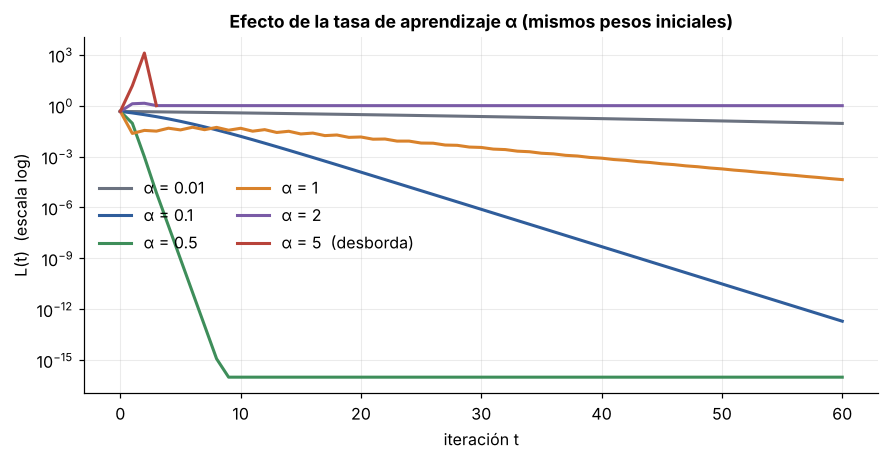

In [11]:
def trayectoria(a, n=60):
    """Gradiente descendente con tasa a durante n pasos. Devuelve (pérdidas, pesos finales); nan si diverge."""
    w = w0.copy(); out = [perdida(w)]
    with np.errstate(all="ignore"):
        for _ in range(n):
            g, _ = gradientes(w); w = w - a * g; out.append(perdida(w))
    return np.array(out), w

alphas = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]
tray, w_fin = {}, {}
for a in alphas:
    tray[a], w_fin[a] = trayectoria(a)
res = []
for a, tr in tray.items():
    finito = np.isfinite(tr).all()
    monot = bool(finito and np.all(np.diff(tr) <= 1e-15))
    with np.errstate(all="ignore"):
        yh_fin = adelante(w_fin[a])[1]
    res.append({"α": f"{a:g}", "L tras 5 it.": f"{tr[5]:.3e}", "L tras 60 it.": f"{tr[-1]:.3e}", "ŷ tras 60 it.": f"{yh_fin:.4f}",
                "¿descenso monótono?": "sí" if monot else "no", "¿valores finitos?": "sí" if finito else "no (desborda)"})
display(HTML(pd.DataFrame(res).to_html(index=False, border=0, justify="center")))

fig, ax = plt.subplots(figsize=(8.2, 4.3))
colores = [C["gris"], C["azul"], C["verde"], C["naranja"], C["morado"], C["rojo"]]
for (a, tr), col in zip(tray.items(), colores):
    ok = np.isfinite(tr)
    ax.semilogy(np.arange(len(tr))[ok], np.clip(tr[ok], 1e-16, None), "-", lw=2, color=col, label=f"α = {a:g}" + ("" if ok.all() else "  (desborda)"))
ax.set(xlabel="iteración t", ylabel="L(t)  (escala log)", title="Efecto de la tasa de aprendizaje α (mismos pesos iniciales)")
ax.legend(ncol=2); fig.tight_layout()

In [12]:
# Hessiana de L en los pesos iniciales (por diferencias finitas de los gradientes analíticos): umbral local de estabilidad 2/λmax
def hessiana(w, h=1e-5):
    H = np.zeros((6, 6))
    for i in range(6):
        e = np.zeros(6); e[i] = h
        H[:, i] = (gradientes(w + e)[0] - gradientes(w - e)[0]) / (2 * h)
    return (H + H.T) / 2
lam = np.linalg.eigvalsh(hessiana(w0))
print("Autovalores de la hessiana de L en ω(0):", np.round(lam, 4))
print(f"λmax = {lam.max():.4f}   →   umbral local de estabilidad 2/λmax = {2/lam.max():.3f}")

Autovalores de la hessiana de L en ω(0): [-0.7936 -0.1594 -0.      0.      0.5378  0.9916]
λmax = 0.9916   →   umbral local de estabilidad 2/λmax = 2.017


**Respuesta 2.** *Por qué son pequeños:* el cambio es proporcional a $\alpha\cdot\nabla L$; con $\alpha=0.01$ y gradientes de entre $0.02$ y $0.57$ en valor absoluto, cada peso se mueve milésimas por paso
(máximo $\approx 0.0057$, y $\approx 0.028$ acumulado tras cinco iteraciones). La función de pérdida es suave, así que un paso corto basta para garantizar descenso, pero también avanza poco: la pérdida baja unas $0.0087$ por iteración.

*Con $\alpha$ mayor* se espera un descenso **más rápido**, porque cada paso recorre más distancia: en el experimento, $\alpha=0.1$ lleva la pérdida a $\approx 0.12$ en cinco iteraciones y $\alpha=0.5$ a $\approx 10^{-9}$.
Pero la ventaja tiene un límite: para $\alpha$ demasiado grande el paso sobrepasa la zona donde el desarrollo de primer orden es válido y el descenso deja de ser monótono, puede quedar atrapado en zonas saturadas
de la sigmoide, o diverger. En el experimento, $\alpha=1$ ya no es monótono, $\alpha=2$ se queda en $L\approx 1$ (la red salta a una región saturada con $\hat y\approx0$ y gradientes casi nulos) y $\alpha=5$ desborda.
Para una función cuadrática el umbral de estabilidad es $\alpha<2/\lambda_{\max}$, con $\lambda_{\max}$ el mayor autovalor de la matriz hessiana (es el mismo resultado de la sección 3); aquí la hessiana de $L$ en los pesos iniciales tiene
$\lambda_{\max}\approx 0.99$, lo que da un umbral local $\approx 2.0$. La red no es cuadrática, de modo que ese umbral es solo orientativo.

### 1.9 Pregunta 3 — ¿Cuántas iteraciones adicionales hasta que $|\Delta L|<10^{-6}$?

Con solo cinco iteraciones no hay una cifra «exacta»: hay que **extrapolar**. Hacemos dos cosas: (a) una estimación a partir de un modelo geométrico y (b) la simulación del criterio de parada, que sirve de verificación.

**Modelo.** Si $\hat y$ es cercano al objetivo, un paso cambia el error $e=y-\hat y$ en $\Delta\hat y\approx-\alpha\nabla\hat y\cdot\nabla L=2\alpha e\,\|\nabla\hat y\|^2$, por lo que $e^{(t+1)}\approx e^{(t)}\bigl(1-2\alpha\|\nabla\hat y\|^2\bigr)$ y
$L=e^2$ decrece geométricamente con razón $\rho=(1-2\alpha\|\nabla\hat y\|^2)^2$. El criterio $|\Delta L|=L(1-\rho)<10^{-6}$ se cumple cuando $L<10^{-6}/(1-\rho)$.

In [13]:
def norma2_grad_yhat(w):
    g, dL = gradientes(w)
    return np.sum((g / dL) ** 2)          # ‖∇ŷ‖²: como ∇L = (∂L/∂ŷ)·∇ŷ, se tiene g/dL = ∇ŷ

# (b) Simulación del criterio de parada |L(t) − L(t−1)| < 1e-6
TOL = 1e-6
w = w0.copy(); Ls = [perdida(w)]; ng = [norma2_grad_yhat(w)]; t = 0
while True:
    g, _ = gradientes(w); w = w - alpha * g; Ls.append(perdida(w)); ng.append(norma2_grad_yhat(w)); t += 1
    if abs(Ls[-1] - Ls[-2]) < TOL or t > 100000:
        break
Ls = np.array(Ls); ng = np.array(ng); dLs = np.abs(np.diff(Ls)); t_star = t
print(f"Simulación: |L(t) − L(t−1)| < {TOL:g} por primera vez en t* = {t_star}  (L = {Ls[t_star]:.3e}).")
print(f"Iteraciones adicionales a las 5 ya hechas: {t_star - N_IT}")

# (a) Estimación con el modelo geométrico, usando solo la información disponible en la iteración t0
def estimar(t0):
    rho = (1 - 2 * alpha * ng[t0]) ** 2
    L_cr = TOL / (1 - rho)                       # pérdida bajo la cual |ΔL| < TOL
    n = np.log(L_cr / Ls[t0]) / np.log(rho)      # iteraciones desde t0 hasta L_cr
    return rho, L_cr, n
filas = []
for t0 in [5, 25, 50, 100, 200]:
    rho, L_cr, n = estimar(t0)
    filas.append({"estimación hecha en t0": t0, "‖∇ŷ‖²": f"{ng[t0]:.4f}", "razón ρ": f"{rho:.4f}", "L crítico": f"{L_cr:.2e}",
                  "t* estimado": f"{t0 + n:.0f}", "t* real (simulación)": t_star})
display(HTML(pd.DataFrame(filas).to_html(index=False, border=0, justify="center")))

Simulación: |L(t) − L(t−1)| < 1e-06 por primera vez en t* = 255  (L = 2.138e-05).
Iteraciones adicionales a las 5 ya hechas: 250


estimación hecha en t0,‖∇ŷ‖²,razón ρ,L crítico,t* estimado,t* real (simulación)
5,0.5112,0.9797,4.92e-05,445,255
25,0.6458,0.9743,3.90e-05,364,255
50,0.8075,0.9680,3.12e-05,305,255
100,1.0080,0.9601,2.51e-05,264,255
200,1.1079,0.9562,2.28e-05,254,255


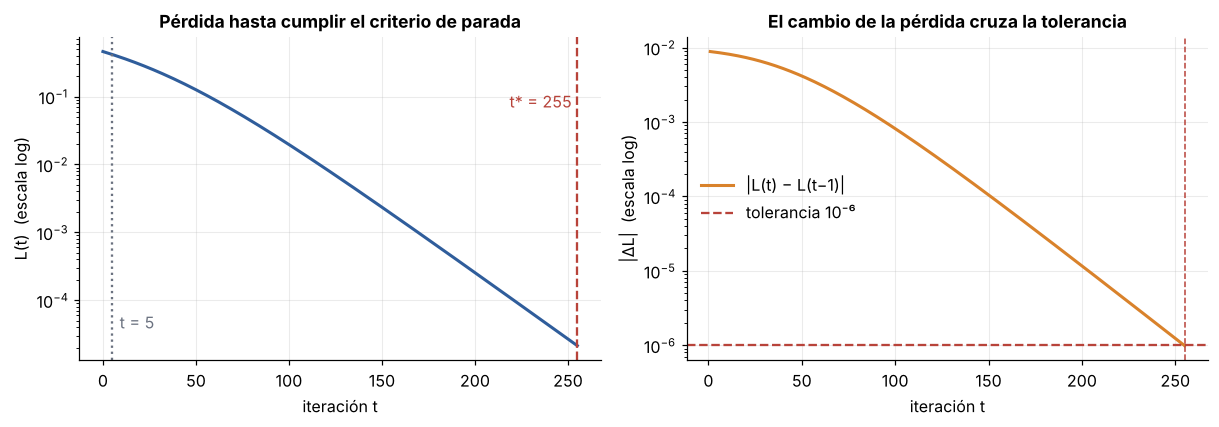

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11.2, 4.0))
ax[0].semilogy(np.arange(len(Ls)), Ls, color=C["azul"], lw=2)
ax[0].axvline(N_IT, color=C["gris"], ls=":", lw=1.5); ax[0].text(N_IT + 4, Ls[-1] * 1.8, "t = 5", color=C["gris"])
ax[0].axvline(t_star, color=C["rojo"], ls="--", lw=1.5); ax[0].text(t_star - 3, Ls[0] * 0.15, f"t* = {t_star}", color=C["rojo"], ha="right")
ax[0].set(xlabel="iteración t", ylabel="L(t)  (escala log)", title="Pérdida hasta cumplir el criterio de parada")
ax[1].semilogy(np.arange(1, len(Ls)), dLs, color=C["naranja"], lw=2, label="|L(t) − L(t−1)|")
ax[1].axhline(TOL, color=C["rojo"], ls="--", lw=1.5, label="tolerancia 10⁻⁶")
ax[1].axvline(t_star, color=C["rojo"], ls="--", lw=1.0)
ax[1].set(xlabel="iteración t", ylabel="|ΔL|  (escala log)", title="El cambio de la pérdida cruza la tolerancia")
ax[1].legend(); fig.tight_layout()

**Respuesta 3.** Si se extrapola con lo que se ve en las primeras iteraciones (la razón local medida en $t=5$, $\rho\approx0.98$) se obtiene $t^*\approx445$, es decir, unas **440** iteraciones adicionales; es una **sobreestimación**, porque la
razón de decaimiento **mejora** a medida que los pesos crecen (el factor $\|\nabla\hat y\|^2$ pasa de $0.51$ a $\approx 1.11$, y $\rho$ de $0.980$ a $0.956$). Con la razón en régimen asintótico el modelo acierta: hecha en $t_0=200$ la estimación da $\approx 254$ frente a $255$ reales.

La simulación del criterio de parada da $t^*=255$, es decir, se necesitan unas **250 iteraciones adicionales** a las cinco ya realizadas para que $|L^{(t)}-L^{(t-1)}|<10^{-6}$, momento en que la pérdida ya es de apenas $\approx 2\times10^{-5}$
(la red prácticamente reproduce $y=1$). Con $\alpha=0.01$ el entrenamiento es lento: la reducción es geométrica con una razón cercana a 1, y la caída por iteración, $\approx 0.0087$ al comienzo, debe bajar cuatro órdenes de magnitud hasta cruzar la tolerancia.

**Conclusión de la sección 1.** Las cinco iteraciones están calculadas con cuatro o más decimales, verificadas con dos implementaciones y con diferencias finitas, y las tres preguntas están respondidas con evidencia numérica.

---
# 2 · Sección 2.9: derivada de la sigmoidea logística

*Fuente: Lección 2 (Multilayer Perceptron), §2.9 «Cálculo de $\delta^r_{nj}$», justo después de la Ec. (2.10); la función se define en §2.5.*

### Enunciado

> El único cálculo que queda es la derivada de $f$. Para el caso de la **función sigmoidea logística** se demuestra fácilmente que es igual a (*verifíquelo*)
>
> $$f'(z)=a\,f(z)\,\bigl(1-f(z)\bigr).$$

Con la definición de la lección (§2.5, «Neurona sigmoidea logística»):

$$
f(z)=\sigma(z):=\frac{1}{1+\exp(-az)},\qquad a>0 .
$$

### Demostración

**Paso 1 (derivar).** Escribimos $f(z)=\bigl(1+e^{-az}\bigr)^{-1}$. Por la regla de la cadena, con $u(z)=1+e^{-az}$ y $u'(z)=-a\,e^{-az}$:

$$
f'(z)=-\,u(z)^{-2}\,u'(z)=-\bigl(1+e^{-az}\bigr)^{-2}\bigl(-a\,e^{-az}\bigr)=\frac{a\,e^{-az}}{\bigl(1+e^{-az}\bigr)^{2}} .
$$

**Paso 2 (separar en dos factores).** El denominador es un cuadrado, así que podemos repartirlo:

$$
f'(z)=a\cdot\underbrace{\frac{1}{1+e^{-az}}}_{=\,f(z)}\cdot\underbrace{\frac{e^{-az}}{1+e^{-az}}}_{=:\,g(z)} .
$$

**Paso 3 (identificar $g$).** Como $1=\dfrac{1+e^{-az}}{1+e^{-az}}$,

$$
1-f(z)=\frac{1+e^{-az}}{1+e^{-az}}-\frac{1}{1+e^{-az}}=\frac{e^{-az}}{1+e^{-az}}=g(z).
$$

**Paso 4 (concluir).** Sustituyendo $g=1-f$ en el Paso 2:

$$
\boxed{\,f'(z)=a\,f(z)\bigl(1-f(z)\bigr)\,}\qquad\blacksquare
$$

### Consecuencias útiles

* **Signo y valor máximo.** Como $0<f(z)<1$, se tiene $f'(z)>0$. El producto $f(1-f)$ alcanza su máximo $1/4$ en $f=1/2$, es decir en $z=0$, así que $\max_z f'(z)=a/4$. Para $|z|$ grande $f'\to0$ (saturación): origen del *gradiente que se desvanece*.
* **Con $a=1$** se obtiene $\sigma'(z)=\sigma(z)(1-\sigma(z))$. Esto coincide con la expresión que usa la lección en el grafo computacional de la §2.7, $\partial p_7/\partial p_5=p_7^2e^{-p_5}$, porque
  $p_7^2e^{-p_5}=p_7\cdot\dfrac{e^{-p_5}}{1+e^{-p_5}}=p_7\,(1-p_7)$ (Paso 3 con $a=1$).
* **En backpropagation** (Ec. 2.10, $\delta^{r-1}_{nj}=e^{r-1}_{nj}f'(z^{r-1}_{nj})$), la derivada se calcula con la activación $f(z)$ ya almacenada en el paso hacia adelante, sin volver a evaluar exponenciales.

### Verificación numérica

✔ f'(z) = a f (1−f) vs derivada numérica (a ∈ {0.5, 1, 2, 5}, z ∈ [−10, 10])  |  error = 1.45e-10  (tolerancia 1.0e-08)
✔ Expresión del Paso 1 = a f (1−f)  |  error = 8.02e-16  (tolerancia 1.0e-14)
✔ Identidad σ² e^{−z} = σ(1−σ) usada en el grafo de la §2.7  |  error = 1.64e-16  (tolerancia 1.0e-14)


a,|f' fórmula − f' numérica| (máx.),|Paso 1 − Paso 4| (máx.),máx f' observado,a/4
0.5000,1.363e-10,7.980e-17,0.1250,0.1250
1.0000,1.447e-10,1.609e-16,0.2500,0.2500
2.0000,1.363e-10,3.190e-16,0.5000,0.5000
5.0000,1.383e-10,8.019e-16,1.2500,1.2500


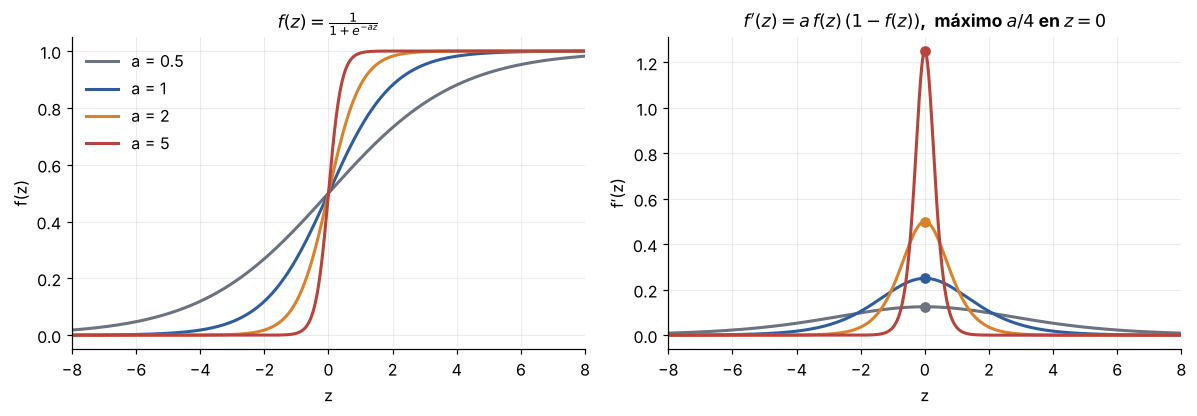

In [15]:
def f_sig(z, a):  return 1.0 / (1.0 + np.exp(-a * z))
def df_formula(z, a):  s = f_sig(z, a); return a * s * (1.0 - s)          # f'(z) = a f (1 - f)
def df_directa(z, a):  return a * np.exp(-a * z) / (1.0 + np.exp(-a * z)) ** 2   # resultado del Paso 1

z = np.linspace(-10, 10, 4001)
filas = []
for a in [0.5, 1.0, 2.0, 5.0]:
    h = 1e-6
    fd = (f_sig(z + h, a) - f_sig(z - h, a)) / (2 * h)                       # derivada numérica (diferencias centrales)
    filas.append({"a": a, "|f' fórmula − f' numérica|  (máx.)": np.abs(df_formula(z, a) - fd).max(),
                  "|Paso 1 − Paso 4|  (máx.)": np.abs(df_directa(z, a) - df_formula(z, a)).max(),
                  "máx f' observado": df_formula(z, a).max(), "a/4": a / 4})
res = pd.DataFrame(filas)
display(HTML(res.to_html(index=False, border=0, justify="center", float_format=lambda v: f"{v:.3e}" if v < 1e-3 else f"{v:.4f}")))
registrar("2", "f'(z) = a f (1−f) vs derivada numérica (a ∈ {0.5, 1, 2, 5}, z ∈ [−10, 10])", res.iloc[:, 1].max(), 1e-8)
registrar("2", "Expresión del Paso 1 = a f (1−f)", res.iloc[:, 2].max(), 1e-14)

# Identidad usada en la §2.7:  p² e^{-p} = p(1 − p)  con p = σ(z) (a = 1)
zz = np.linspace(-8, 8, 2001); p7 = f_sig(zz, 1.0)
registrar("2", "Identidad σ² e^{−z} = σ(1−σ) usada en el grafo de la §2.7", np.abs(p7**2 * np.exp(-zz) - p7 * (1 - p7)).max(), 1e-14)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
cols = [C["gris"], C["azul"], C["naranja"], C["rojo"]]
for a, col in zip([0.5, 1.0, 2.0, 5.0], cols):
    ax[0].plot(z, f_sig(z, a), color=col, lw=2, label=f"a = {a:g}")
    ax[1].plot(z, df_formula(z, a), color=col, lw=2, label=f"a = {a:g}")
    ax[1].plot(0, a / 4, "o", color=col, ms=6)
ax[0].set(title=r"$f(z)=\frac{1}{1+e^{-az}}$", xlabel="z", ylabel="f(z)", xlim=(-8, 8))
ax[1].set(title=r"$f'(z)=a\,f(z)\,(1-f(z))$,  máximo $a/4$ en $z=0$", xlabel="z", ylabel="f′(z)", xlim=(-8, 8))
ax[0].legend(); fig.tight_layout()

**Conclusión de la sección 2.** La identidad $f'(z)=a\,f(z)(1-f(z))$ queda demostrada en cuatro pasos y verificada contra la derivada numérica en
$z\in[-10,10]$ para $a\in\{0.5,1,2,5\}$ (error del orden de $10^{-10}$ o menor); además el máximo $a/4$ se observa en $z=0$.

---
# 3 · Ejercicio de la §2.1: longitud de paso del gradiente descendente con error cuadrático medio

*Fuente: Lección 2 (Multilayer Perceptron), §2.1 «Gradiente descendente», recuadro «Ejercicio» tras la Fig. 2.4.*

### Enunciado

> **Ejercicio**
>
> • Por ejemplo, para el caso de la función de coste del **error cuadrático medio**, la longitud de paso está dada por: $0<\mu<2/\lambda_{\max}$, donde $\lambda_{\max}$ el máximo eigenvalor de la matriz de covarianza $\Sigma_x=\mathbb E[xx^T]$, donde $J(\theta)=E\bigl[(y-\theta^Tx)^2\bigr]$ (ver Sección 5.3 [Theodoridis, 2020]).

La lección define el algoritmo (§2.1) como

$$
\theta^{(i)}=\theta^{(i-1)}-\mu\,\nabla J\bigl(\theta^{(i-1)}\bigr),\qquad \mu>0 \text{ constante},
$$

y pide que $\mu$ garantice «la convergencia a cero del error entre $\theta^{(i)}$ y el mínimo real en forma de serie geométrica».
**Lo que hay que demostrar** es que, para el error cuadrático medio, el algoritmo converge al mínimo desde cualquier punto inicial **si y solo si** $0<\mu<2/\lambda_{\max}$.

### Prerrequisitos (solo lo necesario)

* $\Sigma_x=\mathbb E[xx^T]$ es **simétrica** y semidefinida positiva ($v^T\Sigma_xv=\mathbb E[(v^Tx)^2]\ge0$). Suponemos que es **definida positiva** (todos sus autovalores son $>0$), que es la condición para que el mínimo sea único.
* **Teorema espectral:** existe una matriz ortogonal $U$ ($U^TU=I$) y una diagonal $\Lambda=\operatorname{diag}(\lambda_1,\dots,\lambda_\ell)$ con $\Sigma_x=U\Lambda U^T$; las columnas $u_j$ de $U$ son los autovectores y $\lambda_j>0$ los autovalores.
* **Nota de normalización.** Con $J(\theta)=\mathbb E[(y-\theta^Tx)^2]$ el gradiente es $\nabla J=2(\Sigma_x\theta-p)$, con un factor 2. La cota $2/\lambda_{\max}$ del enunciado corresponde al paso escrito con **ese factor 2 absorbido en $\mu$**, es decir, $\theta^{(i)}=\theta^{(i-1)}-\mu(\Sigma_x\theta^{(i-1)}-p)$ (equivale a minimizar $J/2$). Si se aplica $\nabla J$ de forma literal, la misma condición se escribe $0<\mu<1/\lambda_{\max}$. Demostramos el resultado en general y mostramos ambas versiones.

### Demostración

**Paso 1 (la función de coste es una cuádrica).** Sea $p=\mathbb E[xy]$. Desarrollando el cuadrado y usando la linealidad de la esperanza,

$$
J(\theta)=\mathbb E[y^2]-2\,\theta^Tp+\theta^T\Sigma_x\theta .
$$

Como $\Sigma_x$ es simétrica, $\nabla(\theta^T\Sigma_x\theta)=2\Sigma_x\theta$, y entonces

$$
\nabla J(\theta)=2\,(\Sigma_x\theta-p).
$$

**Paso 2 (el mínimo).** $\nabla J(\theta_*)=0\iff\Sigma_x\theta_*=p$, luego $\theta_*=\Sigma_x^{-1}p$. Es el único mínimo, porque la hessiana $2\Sigma_x$ es definida positiva. Además $p=\Sigma_x\theta_*$, así que $\nabla J(\theta)=2\Sigma_x(\theta-\theta_*)$.

**Paso 3 (recursión del error).** Sea $\mu$ el coeficiente efectivo del paso con el factor 2 absorbido: $\theta^{(i)}=\theta^{(i-1)}-\mu\,\Sigma_x(\theta^{(i-1)}-\theta_*)$. Restando $\theta_*$ a ambos lados y llamando $e^{(i)}=\theta^{(i)}-\theta_*$,

$$
e^{(i)}=(I-\mu\Sigma_x)\,e^{(i-1)}\quad\Longrightarrow\quad e^{(i)}=(I-\mu\Sigma_x)^{\,i}\,e^{(0)} .
$$

**Paso 4 (desacoplar con la base de autovectores).** Sustituimos $\Sigma_x=U\Lambda U^T$ y definimos las coordenadas $c^{(i)}=U^Te^{(i)}$. Como $I-\mu\Sigma_x=U(I-\mu\Lambda)U^T$,

$$
c^{(i)}=(I-\mu\Lambda)\,c^{(i-1)}\quad\Longrightarrow\quad c_j^{(i)}=(1-\mu\lambda_j)^{\,i}\,c_j^{(0)},\qquad j=1,\dots,\ell,
$$

y, por ser $U$ ortogonal, $\|e^{(i)}\|^2=\sum_j(1-\mu\lambda_j)^{2i}\,\bigl(c_j^{(0)}\bigr)^2$.

**Paso 5 (condición suficiente).** Si $|1-\mu\lambda_j|<1$ para todo $j$, cada $(1-\mu\lambda_j)^i\to0$ y por tanto $e^{(i)}\to0$ para cualquier $e^{(0)}$.
Como $\lambda_j>0$ y $\mu>0$:

$$
|1-\mu\lambda_j|<1\iff -1<1-\mu\lambda_j<1\iff 0<\mu\lambda_j<2\iff \mu<\frac{2}{\lambda_j}.
$$

Se cumple para todo $j$ si y solo si $\mu<2/\lambda_{\max}$.

**Paso 6 (condición necesaria).** Si $\mu\ge2/\lambda_{\max}$ (o $\mu\le0$), entonces $|1-\mu\lambda_{\max}|\ge1$. Tomamos $e^{(0)}=u_{\max}$ (el autovector de $\lambda_{\max}$): $\|e^{(i)}\|=|1-\mu\lambda_{\max}|^{\,i}\ge1$ para todo $i$, de modo que el error **no** tiende a cero. Hay un punto inicial para el que el método no converge.

**Paso 7 (conclusión y velocidad).** El método converge para todo $\theta^{(0)}$ si y solo si

$$
\boxed{\,0<\mu<\frac{2}{\lambda_{\max}}\,}\qquad\blacksquare
$$

y entonces $\|e^{(i)}\|\le\rho^{\,i}\|e^{(0)}\|$ con $\rho(\mu)=\max_j|1-\mu\lambda_j|<1$: el error decae como una **serie geométrica**, justo lo que pide la lección. Además $J(\theta^{(i)})-J(\theta_*)=(e^{(i)})^T\Sigma_xe^{(i)}\to0$.

**Corolario (paso con el gradiente literal).** Si el paso es $\theta^{(i)}=\theta^{(i-1)}-\mu_{\nabla}\nabla J=\theta^{(i-1)}-2\mu_{\nabla}\Sigma_x(\theta^{(i-1)}-\theta_*)$, el coeficiente efectivo es $\mu=2\mu_\nabla$ y la condición se escribe $0<\mu_\nabla<1/\lambda_{\max}$.

**Complemento (paso óptimo).** $\rho(\mu)=\max\{|1-\mu\lambda_{\min}|,\,|1-\mu\lambda_{\max}|\}$ es mínimo cuando ambos términos se igualan, $1-\mu\lambda_{\min}=\mu\lambda_{\max}-1$, es decir

$$
\mu_{\rm opt}=\frac{2}{\lambda_{\max}+\lambda_{\min}},\qquad \rho_{\rm opt}=\frac{\lambda_{\max}-\lambda_{\min}}{\lambda_{\max}+\lambda_{\min}}=\frac{\kappa-1}{\kappa+1},\quad \kappa=\frac{\lambda_{\max}}{\lambda_{\min}} .
$$

Cuanto peor condicionada está $\Sigma_x$ ($\kappa$ grande), más lenta es la convergencia.

### Verificación numérica

Generamos datos $(x_n,y_n)$ con características correlacionadas y usamos las versiones muestrales $\hat\Sigma=\frac1N\sum x_nx_n^T$, $\hat p=\frac1N\sum x_ny_n$, de modo que $J(\theta)=\frac1N\sum(y_n-\theta^Tx_n)^2$ cumple exactamente las fórmulas anteriores.
Comprobamos (i) el gradiente, (ii) la fórmula cerrada del error del Paso 4, (iii) la frontera $2/\lambda_{\max}$ (y $1/\lambda_{\max}$ con gradiente literal) y (iv) el paso óptimo.

In [16]:
rng = np.random.default_rng(7)
N, d = 4000, 3
A_mez = np.array([[1.0, 0.0, 0.0], [0.8, 0.6, 0.0], [0.3, -0.4, 0.5]])      # mezcla lineal → características correlacionadas
X = rng.standard_normal((N, d)) @ A_mez.T                                    # (N, 3)
theta_verd = np.array([1.5, -2.0, 0.7])
yv = X @ theta_verd + 0.5 * rng.standard_normal(N)                           # (N,)

Sigma = X.T @ X / N                  # Σ̂ ≈ E[x xᵀ]   (3×3)
p_xy  = X.T @ yv / N                 # p̂ ≈ E[x y]    (3,)
lam, U = np.linalg.eigh(Sigma)       # autovalores crecientes y autovectores
lam_min, lam_max = lam[0], lam[-1]
theta_star = np.linalg.solve(Sigma, p_xy)
print("Autovalores de Σ̂:", np.round(lam, 4), f"  →  λmax = {lam_max:.4f},  λmin = {lam_min:.4f},  κ = {lam_max/lam_min:.2f}")
print("θ* = Σ̂⁻¹ p̂ =", np.round(theta_star, 4))

J      = lambda th: np.mean((yv - X @ th) ** 2)
grad_J = lambda th: 2.0 * (Sigma @ th - p_xy)                                # fórmula del Paso 1
th_t = np.array([0.3, 0.1, -0.5])
registrar("3", "J(θ) = E[y²] − 2θᵀp + θᵀΣθ", abs(J(th_t) - (np.mean(yv**2) - 2 * th_t @ p_xy + th_t @ Sigma @ th_t)), 1e-12)
registrar("3", "∇J = 2(Σθ − p) vs diferencias finitas", np.abs(grad_J(th_t) - dif_central(J, th_t, 1e-6)).max(), 1e-7)

Autovalores de Σ̂: [0.0856 0.5691 1.8215]   →  λmax = 1.8215,  λmin = 0.0856,  κ = 21.27
θ* = Σ̂⁻¹ p̂ = [ 1.5217 -2.0203  0.6876]
✔ J(θ) = E[y²] − 2θᵀp + θᵀΣθ  |  error = 8.88e-16  (tolerancia 1.0e-12)
✔ ∇J = 2(Σθ − p) vs diferencias finitas  |  error = 1.50e-10  (tolerancia 1.0e-07)


In [17]:
e0 = np.array([1.0, -1.0, 1.0]); e0 = e0 / np.linalg.norm(e0)        # error inicial con componentes en todos los autovectores
c0 = U.T @ e0                                                       # coordenadas c(0) = Uᵀ e(0)

def error_cerrado(mu, i):
    """Paso 4: ‖e(i)‖ = sqrt( Σ_j (1 − μ λj)^(2i) c_j(0)² )."""
    return np.sqrt(np.sum(((1 - mu * lam) ** i * c0) ** 2))

def simular(mu, n_iter, literal=False):
    """Gradiente descendente real. literal=True usa θ ← θ − μ∇J; si no, θ ← θ − μ(Σθ − p) (factor 2 absorbido)."""
    th = theta_star + e0; errs = [np.linalg.norm(th - theta_star)]
    for _ in range(n_iter):
        g = grad_J(th) if literal else (Sigma @ th - p_xy)
        th = th - mu * g; errs.append(np.linalg.norm(th - theta_star))
    return np.array(errs)

# (ii) La fórmula cerrada del Paso 4 reproduce la simulación
err_max = 0.0
for c in [0.3, 0.9, 1.05]:
    mu = c * 2 / lam_max; sim = simular(mu, 40)
    cer = np.array([error_cerrado(mu, i) for i in range(41)])
    err_max = max(err_max, np.max(np.abs(sim - cer) / np.maximum(cer, 1e-300)))
registrar("3", "Fórmula cerrada ‖e(i)‖ del Paso 4 vs simulación (error relativo)", err_max, 1e-9)

# J(θ) − J(θ*) = eᵀ Σ e
th_a = theta_star + np.array([0.4, -0.2, 0.3]); ee = th_a - theta_star
registrar("3", "J(θ) − J(θ*) = (θ−θ*)ᵀ Σ (θ−θ*)", abs(J(th_a) - J(theta_star) - ee @ Sigma @ ee), 1e-12)

✔ Fórmula cerrada ‖e(i)‖ del Paso 4 vs simulación (error relativo)  |  error = 6.04e-14  (tolerancia 1.0e-09)
✔ J(θ) − J(θ*) = (θ−θ*)ᵀ Σ (θ−θ*)  |  error = 8.88e-16  (tolerancia 1.0e-12)


In [18]:
# (iii) Frontera de convergencia: μ = c · 2/λmax (factor 2 absorbido) y μ∇ = c · 1/λmax (gradiente literal)
N_IT = 300; filas = []; viol = 0.0
comp_max = abs(c0[-1])                            # |componente de e(0) sobre el autovector dominante|
for etiqueta, literal, base in [("μ(Σθ−p): factor 2 absorbido", False, 2 / lam_max), ("μ∇J: gradiente literal", True, 1 / lam_max)]:
    for c in [0.5, 0.9, 0.99, 1.0, 1.01, 1.1]:
        mu = c * base
        mu_ef = 2 * mu if literal else mu                      # coeficiente efectivo del Paso 3
        rho = np.max(np.abs(1 - mu_ef * lam))
        sim = simular(mu, N_IT, literal); razon = sim[-1] / sim[0]
        if rho < 1:                                            # debe cumplirse ‖e(i)‖ ≤ ρ^i ‖e(0)‖
            viol = max(viol, razon - (rho ** N_IT + 1e-12))
        else:                                                  # no puede bajar de la componente sobre el autovector dominante
            viol = max(viol, comp_max - 1e-9 - razon)
        filas.append({"regla": etiqueta, "μ": f"{mu:.4f}", "c": f"{c:.2f}", "ρ teórico": f"{rho:.4f}",
                      f"‖e({N_IT})‖/‖e(0)‖ observado": f"{razon:.3e}", f"cota ρ^{N_IT}": f"{rho**N_IT:.3e}",
                      "teoría": "converge" if rho < 1 else ("no converge" if rho == 1 or rho - 1 < 1e-9 else "diverge")})
display(HTML(pd.DataFrame(filas).to_html(index=False, border=0, justify="center")))
registrar("3", "Frontera 2/λmax (1/λmax con gradiente literal): ‖e‖ ≤ ρ^i‖e(0)‖ si ρ<1 y sin decaimiento si ρ≥1", max(viol, 0.0), 1e-9)

✔ Frontera 2/λmax (1/λmax con gradiente literal): ‖e‖ ≤ ρ^i‖e(0)‖ si ρ<1 y sin decaimiento si ρ≥1  |  error = 0.00e+00  (tolerancia 1.0e-09)


regla,μ,c,ρ teórico,‖e(300)‖/‖e(0)‖ observado,cota ρ^300,teoría
μ(Σθ−p): factor 2 absorbido,0.5490,0.50,0.9530,2.352e-07,5.318e-07,converge
μ(Σθ−p): factor 2 absorbido,0.9882,0.90,0.9154,1.334e-12,3.015e-12,converge
μ(Σθ−p): factor 2 absorbido,1.0870,0.99,0.9800,2.865e-04,2.333e-03,converge
μ(Σθ−p): factor 2 absorbido,1.0980,1.00,1.0000,1.228e-01,1.000e+00,no converge
μ(Σθ−p): factor 2 absorbido,1.1090,1.01,1.0200,4.670e+01,3.802e+02,diverge
μ(Σθ−p): factor 2 absorbido,1.2078,1.10,1.2000,6.976e+22,5.680e+23,diverge
μ∇J: gradiente literal,0.2745,0.50,0.9530,2.352e-07,5.318e-07,converge
μ∇J: gradiente literal,0.4941,0.90,0.9154,1.334e-12,3.015e-12,converge
μ∇J: gradiente literal,0.5435,0.99,0.9800,2.865e-04,2.333e-03,converge
μ∇J: gradiente literal,0.5490,1.00,1.0000,1.228e-01,1.000e+00,no converge


✔ Mínimo de ρ(μ) en μopt = 2/(λmax+λmin)  |  error = 2.49e-04  (tolerancia 2.0e-03)
✔ ρ(μopt) = (κ−1)/(κ+1)  |  error = 2.24e-05  (tolerancia 1.0e-03)


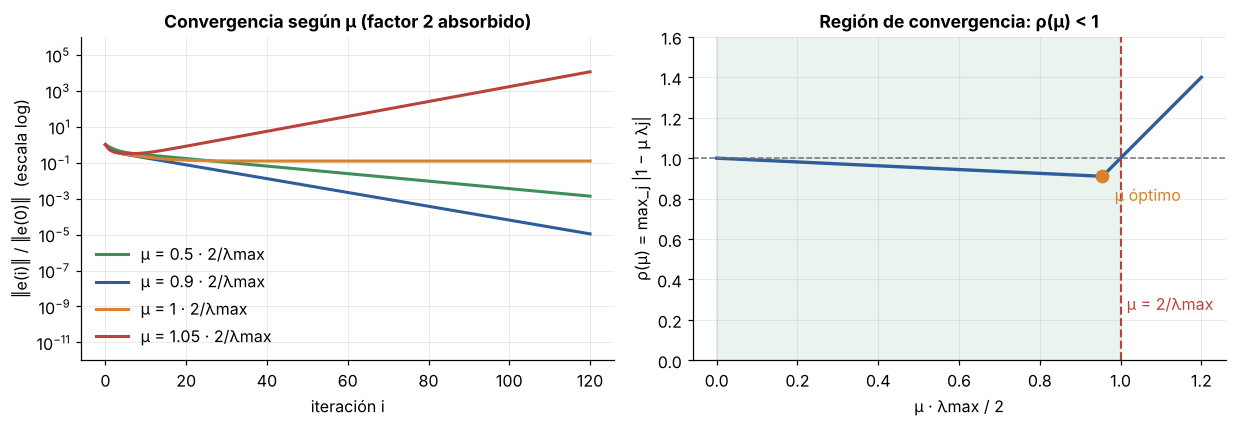

In [19]:
# (iv) Paso óptimo y forma de ρ(μ)
mus = np.linspace(1e-4, 2.4 / lam_max, 4000)
rho_mu = np.array([np.max(np.abs(1 - m * lam)) for m in mus])
mu_opt = 2 / (lam_max + lam_min); rho_opt = (lam_max - lam_min) / (lam_max + lam_min)
registrar("3", "Mínimo de ρ(μ) en μopt = 2/(λmax+λmin)", abs(mus[np.argmin(rho_mu)] - mu_opt) / mu_opt, 2e-3)
registrar("3", "ρ(μopt) = (κ−1)/(κ+1)", abs(rho_mu.min() - rho_opt), 1e-3)

fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.0))
for c, col in zip([0.5, 0.9, 1.0, 1.05], [C["verde"], C["azul"], C["naranja"], C["rojo"]]):
    e = simular(c * 2 / lam_max, 120)
    ax[0].semilogy(e / e[0], color=col, lw=2, label=f"μ = {c:g} · 2/λmax")
ax[0].set(xlabel="iteración i", ylabel="‖e(i)‖ / ‖e(0)‖  (escala log)", title="Convergencia según μ (factor 2 absorbido)")
ax[0].legend(loc="lower left"); ax[0].set_ylim(1e-12, 1e6)
ax[1].plot(mus * lam_max / 2, rho_mu, color=C["azul"], lw=2.2)
ax[1].axhline(1, color=C["gris"], ls="--", lw=1)
ax[1].axvline(1, color=C["rojo"], ls="--", lw=1.4); ax[1].text(1.015, 0.25, "μ = 2/λmax", color=C["rojo"])
ax[1].plot(mu_opt * lam_max / 2, rho_opt, "o", color=C["naranja"], ms=8); ax[1].annotate("μ óptimo", (mu_opt * lam_max / 2, rho_opt), textcoords="offset points", xytext=(8, -16), color=C["naranja"])
ax[1].fill_between(mus * lam_max / 2, 0, 3, where=rho_mu < 1, color=C["verde"], alpha=0.10)
ax[1].set(xlabel="μ · λmax / 2", ylabel="ρ(μ) = max_j |1 − μ λj|", title="Región de convergencia: ρ(μ) < 1", ylim=(0, 1.6))
fig.tight_layout()

**Conclusión de la sección 3.** Con $J(\theta)=\mathbb E[(y-\theta^Tx)^2]$ el error de gradiente descendente evoluciona como $e^{(i)}=(I-\mu\Sigma_x)^ie^{(0)}$, que en la base de autovectores se desacopla en
$c_j^{(i)}=(1-\mu\lambda_j)^ic_j^{(0)}$. La convergencia para todo punto inicial ocurre **si y solo si** $0<\mu<2/\lambda_{\max}$ (con el factor 2 del gradiente absorbido en $\mu$; con el gradiente literal, $0<\mu<1/\lambda_{\max}$).
La simulación confirma la frontera: con $c<1$ el error decae geométricamente con la razón $\rho$ predicha y con $c>1$ crece; en $c=1$ la componente del autovector dominante no decae.

---
# 4 · Proposición 3.1: gradientes de una capa convolucional

*Fuente: Lección 3 (Convolutional Neural Networks), Proposición 3.1; la operación se define en la Ec. (3.1).*

### Enunciado

> **Proposition 3.1 (Gradientes de una capa convolucional)**
>
> Sea $O(i,j)=\sum_{t=1}^{m}\sum_{r=1}^{m}h(t,r)\,I(i+t-1,\,j+r-1)+b$ como en la Eq. (3.1), con $I\in\mathbb R^{l\times l}$, *stride* 1 y sin *padding*, de modo que $O\in\mathbb R^{k\times k}$ con $k=l-m+1$.
> Si $\delta(i,j)=\partial\mathcal L/\partial O(i,j)$ (extendida con ceros fuera de $\{1,\dots,k\}^2$), entonces
>
> $$
> \frac{\partial\mathcal L}{\partial h(t,r)}=\sum_{i,j=1}^{k}\delta(i,j)\,I(i+t-1,\,j+r-1),\qquad
> \frac{\partial\mathcal L}{\partial I(u,v)}=\sum_{t,r=1}^{m}h(t,r)\,\delta(u-t+1,\,v-r+1),\qquad
> \frac{\partial\mathcal L}{\partial b}=\sum_{i,j}\delta(i,j).
> $$

### Demostración

**Paso 0 (índices y buena definición).** Sean $\Omega_I=\{1,\dots,l\}^2$ (píxeles de la entrada), $\Omega_h=\{1,\dots,m\}^2$ (posiciones del filtro) y $\Omega_O=\{1,\dots,k\}^2$ (posiciones de la salida).
Para $(i,j)\in\Omega_O$ y $(t,r)\in\Omega_h$ se tiene $1\le i+t-1\le k+m-1=l$, y lo mismo para $j+r-1$; por tanto $(i+t-1,\,j+r-1)\in\Omega_I$ y todos los términos de $O(i,j)$ usan píxeles que existen. Esto es lo que garantizan las hipótesis *stride* 1 y sin *padding* con $k=l-m+1$.
Las cantidades $h(t,r)$, $I(u,v)$ y $b$ se tratan como variables independientes: $\dfrac{\partial h(t',r')}{\partial h(t,r)}=\mathbf 1_{\{t'=t,\,r'=r\}}$, y análogamente para $I$.

**Paso 1 (regla de la cadena para la capa).** La pérdida depende de los parámetros y de la entrada **solo a través de $O$**: $\mathcal L=F(O)$, donde $F:\mathbb R^{k\times k}\to\mathbb R$ es $C^1$ y representa las capas posteriores y la pérdida. Con $\delta(i,j)=\partial F/\partial O(i,j)$ y $p$ cualquiera de las variables $h(t,r)$, $I(u,v)$ o $b$,

$$
\frac{\partial\mathcal L}{\partial p}=\sum_{(i,j)\in\Omega_O}\frac{\partial F}{\partial O(i,j)}\,\frac{\partial O(i,j)}{\partial p}=\sum_{(i,j)\in\Omega_O}\delta(i,j)\,\frac{\partial O(i,j)}{\partial p}.\tag{*}
$$

Todo se reduce a calcular las derivadas $\partial O(i,j)/\partial p$.

**Paso 2 (tres derivadas de $O$).** $O(i,j)=\sum_{(t',r')\in\Omega_h}h(t',r')\,I(i+t'-1,\,j+r'-1)+b$ es una suma finita de productos de una variable del filtro por una de la entrada, más $b$. Derivando término a término:

* **(a) Respecto de un peso.** Solo el término $(t',r')=(t,r)$ depende de $h(t,r)$: $\ \dfrac{\partial O(i,j)}{\partial h(t,r)}=I(i+t-1,\,j+r-1)$.
* **(b) Respecto del sesgo.** $\ \dfrac{\partial O(i,j)}{\partial b}=1$.
* **(c) Respecto de un píxel.** $\ \dfrac{\partial O(i,j)}{\partial I(u,v)}=\sum_{(t',r')\in\Omega_h}h(t',r')\,\mathbf 1_{\{i+t'-1=u,\ j+r'-1=v\}}$.
  Para $(i,j)$ fijo, la condición determina $(t',r')=(u-i+1,\,v-j+1)$. Por tanto la derivada vale $h(u-i+1,\,v-j+1)$ si ese par pertenece a $\Omega_h$ y $0$ en caso contrario.

**Paso 3 (primera y tercera fórmulas).** Sustituyendo (a) y (b) en $(*)$:

$$
\frac{\partial\mathcal L}{\partial h(t,r)}=\sum_{i,j=1}^{k}\delta(i,j)\,I(i+t-1,\,j+r-1),\qquad
\frac{\partial\mathcal L}{\partial b}=\sum_{i,j}\delta(i,j).
$$

**Paso 4 (segunda fórmula: cambio de índice).** Sustituyendo (c) en $(*)$, para $(u,v)\in\Omega_I$:

$$
\frac{\partial\mathcal L}{\partial I(u,v)}=\sum_{(i,j)\in\Omega_O}\delta(i,j)\,h(u-i+1,\,v-j+1)\,\mathbf 1_{\{(u-i+1,\ v-j+1)\in\Omega_h\}} .
$$

Hacemos el cambio de variables $(t,r)=(u-i+1,\,v-j+1)$, equivalente a $(i,j)=(u-t+1,\,v-r+1)$. Es una **biyección** entre los pares $(i,j)$ con $(u-i+1,v-j+1)\in\Omega_h$ y los pares $(t,r)\in\Omega_h$. La suma se reescribe, entonces, sobre el filtro:

$$
\frac{\partial\mathcal L}{\partial I(u,v)}=\sum_{(t,r)\in\Omega_h}h(t,r)\,\delta(u-t+1,\,v-r+1)\,\mathbf 1_{\{(u-t+1,\ v-r+1)\in\Omega_O\}} .
$$

El indicador solo elimina los términos en que $(u-t+1,v-r+1)\notin\Omega_O$, y para esos $\delta$ vale $0$ por la extensión con ceros del enunciado. Podemos, pues, quitarlo y llegar a la fórmula pedida,

$$
\frac{\partial\mathcal L}{\partial I(u,v)}=\sum_{t,r=1}^{m}h(t,r)\,\delta(u-t+1,\,v-r+1).\qquad\blacksquare
$$

**Observaciones.**
(i) La extensión con ceros no es un adorno: refleja que los píxeles de los bordes participan en menos salidas. Por ejemplo, el píxel de la esquina $I(1,1)$ solo interviene en $O(1,1)$, y la fórmula da $\partial\mathcal L/\partial I(1,1)=h(1,1)\,\delta(1,1)$, pues es el único $(t,r)$ con $(2-t,2-r)\in\Omega_O$.
(ii) Interpretación: $\partial\mathcal L/\partial h$ es la **correlación cruzada** válida de $I$ con $\delta$; $\partial\mathcal L/\partial I$ es la **convolución completa** de $\delta$ con $h$ (equivalente a correlacionar $\delta$, rellenada con ceros, con el filtro rotado 180°).

### Verificación numérica

Usamos una pérdida **no lineal** $F(O)=\sum_{ij}\bigl(\tfrac12A_{ij}O_{ij}^2+B_{ij}\sin O_{ij}\bigr)$ con $A,B$ aleatorias, de modo que $\delta=A\odot O+B\odot\cos O$ no sea trivial.
Calculamos los gradientes con las fórmulas de la proposición (implementadas con los índices tal como están escritos) y los comparamos con **diferencias finitas** sobre la pérdida completa, para una configuración y luego para **los 45 pares** $(l,m)$ con $1\le m\le l\le 9$ (incluidos los casos extremos $m=1$ y $m=l$).

In [20]:
rng = np.random.default_rng(11)

def salida_conv(I, h, b):
    """O(i,j) = Σ_{t,r} h(t,r) I(i+t−1, j+r−1) + b  (Ec. 3.1, stride 1, sin padding)."""
    m = h.shape[0]; k = I.shape[0] - m + 1
    return np.array([[np.sum(h * I[i:i + m, j:j + m]) + b for j in range(k)] for i in range(k)])   # (k, k)

def crear_problema(l, m):
    I = rng.standard_normal((l, l)); h = rng.standard_normal((m, m)); b = float(rng.standard_normal())
    k = l - m + 1
    Aw = rng.uniform(0.5, 1.5, (k, k)); Bw = rng.standard_normal((k, k))
    F = lambda O: np.sum(0.5 * Aw * O ** 2 + Bw * np.sin(O))                  # pérdida posterior F(O)  (C¹, no lineal)
    dF = lambda O: Aw * O + Bw * np.cos(O)                                     # δ = ∂F/∂O
    return I, h, b, F, dF

def gradientes_prop31(I, h, b, delta):
    """Las tres fórmulas de la Proposición 3.1, con los índices 1-based del enunciado."""
    l = I.shape[0]; m = h.shape[0]; k = l - m + 1
    d = lambda i, j: delta[i - 1, j - 1] if (1 <= i <= k and 1 <= j <= k) else 0.0     # δ extendida con ceros
    dh = np.array([[sum(delta[i - 1, j - 1] * I[i + t - 2, j + r - 2] for i in range(1, k + 1) for j in range(1, k + 1))
                    for r in range(1, m + 1)] for t in range(1, m + 1)])
    dI = np.array([[sum(h[t - 1, r - 1] * d(u - t + 1, v - r + 1) for t in range(1, m + 1) for r in range(1, m + 1))
                    for v in range(1, l + 1)] for u in range(1, l + 1)])
    return dh, dI, float(np.sum(delta))

def gradientes_fd(I, h, b, F):
    l, m = I.shape[0], h.shape[0]
    L_h = lambda x: F(salida_conv(I, x.reshape(m, m), b)); L_I = lambda x: F(salida_conv(x.reshape(l, l), h, b)); L_b = lambda x: F(salida_conv(I, h, x[0]))
    return dif_central(L_h, h.ravel()).reshape(m, m), dif_central(L_I, I.ravel()).reshape(l, l), dif_central(L_b, np.array([b]))[0]

# --- una configuración: l = 7, m = 3 (k = 5) ---
l, m = 7, 3
I, h, b, F, dF = crear_problema(l, m)
O = salida_conv(I, h, b); delta = dF(O)
dh, dI, db = gradientes_prop31(I, h, b, delta)
dh_fd, dI_fd, db_fd = gradientes_fd(I, h, b, F)
registrar("4", "∂L/∂h(t,r): fórmula de la proposición vs diferencias finitas (l=7, m=3)", np.abs(dh - dh_fd).max(), 1e-7)
registrar("4", "∂L/∂I(u,v): fórmula de la proposición vs diferencias finitas (l=7, m=3)", np.abs(dI - dI_fd).max(), 1e-7)
registrar("4", "∂L/∂b: fórmula de la proposición vs diferencias finitas (l=7, m=3)", abs(db - db_fd), 1e-7)
registrar("4", "Observación (i): ∂L/∂I(1,1) = h(1,1) δ(1,1)", abs(dI[0, 0] - h[0, 0] * delta[0, 0]), 1e-12)

# --- contraste adicional con scipy (si está disponible): correlación válida y convolución completa ---
if _sig is not None:
    registrar("4", "∂L/∂h = correlate2d(I, δ, 'valid')  (scipy)", np.abs(dh - _sig.correlate2d(I, delta, mode="valid")).max(), 1e-12)
    registrar("4", "∂L/∂I = convolve2d(δ, h, 'full')  (scipy)", np.abs(dI - _sig.convolve2d(delta, h, mode="full")).max(), 1e-12)
else:
    print("(scipy no disponible: se omite el contraste con scipy.signal)")

✔ ∂L/∂h(t,r): fórmula de la proposición vs diferencias finitas (l=7, m=3)  |  error = 1.20e-08  (tolerancia 1.0e-07)
✔ ∂L/∂I(u,v): fórmula de la proposición vs diferencias finitas (l=7, m=3)  |  error = 1.75e-08  (tolerancia 1.0e-07)
✔ ∂L/∂b: fórmula de la proposición vs diferencias finitas (l=7, m=3)  |  error = 4.44e-09  (tolerancia 1.0e-07)
✔ Observación (i): ∂L/∂I(1,1) = h(1,1) δ(1,1)  |  error = 0.00e+00  (tolerancia 1.0e-12)
✔ ∂L/∂h = correlate2d(I, δ, 'valid')  (scipy)  |  error = 7.11e-15  (tolerancia 1.0e-12)
✔ ∂L/∂I = convolve2d(δ, h, 'full')  (scipy)  |  error = 0.00e+00  (tolerancia 1.0e-12)


In [21]:
# --- todos los tamaños 1 ≤ m ≤ l ≤ 9 (45 pares), incluidos m = 1 y m = l ---
peor = 0.0
elegidos = [(l_, m_) for l_ in range(1, 10) for m_ in range(1, l_ + 1)]
for (l_, m_) in elegidos:
    I_, h_, b_, F_, dF_ = crear_problema(l_, m_)
    delta_ = dF_(salida_conv(I_, h_, b_))
    a1, a2, a3 = gradientes_prop31(I_, h_, b_, delta_); f1, f2, f3 = gradientes_fd(I_, h_, b_, F_)
    peor = max(peor, np.abs(a1 - f1).max(), np.abs(a2 - f2).max(), abs(a3 - f3))
print(f"Se probaron {len(elegidos)} pares (l, m) distintos.")
registrar("4", f"Las tres fórmulas vs diferencias finitas en los {len(elegidos)} pares (l, m) con 1 ≤ m ≤ l ≤ 9", peor, 1e-6)

Se probaron 45 pares (l, m) distintos.
✔ Las tres fórmulas vs diferencias finitas en los 45 pares (l, m) con 1 ≤ m ≤ l ≤ 9  |  error = 7.63e-08  (tolerancia 1.0e-06)


Número de salidas O(i,j) que usan cada píxel I(u,v)  (l = 6, m = 3):
[[1 2 3 3 2 1]
 [2 4 6 6 4 2]
 [3 6 9 9 6 3]
 [3 6 9 9 6 3]
 [2 4 6 6 4 2]
 [1 2 3 3 2 1]]


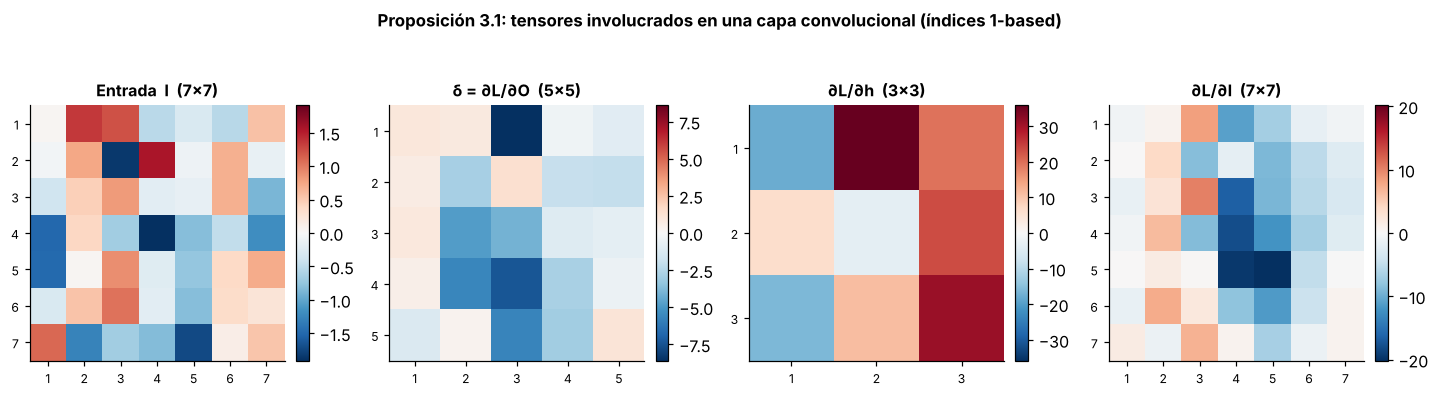

In [22]:
# Cuántas salidas usa cada píxel (explica el efecto de borde de la extensión con ceros): l = 6, m = 3
cuenta = np.zeros((6, 6), dtype=int)
for i in range(4):
    for j in range(4):
        cuenta[i:i + 3, j:j + 3] += 1            # la salida O(i,j) usa una ventana 3×3 de la entrada
print("Número de salidas O(i,j) que usan cada píxel I(u,v)  (l = 6, m = 3):"); print(cuenta)

fig, ax = plt.subplots(1, 4, figsize=(13.2, 3.5))
for a_, M, tit in zip(ax, [I, delta, dh, dI], ["Entrada  I  (7×7)", "δ = ∂L/∂O  (5×5)", "∂L/∂h  (3×3)", "∂L/∂I  (7×7)"]):
    im = a_.imshow(M, cmap="RdBu_r", vmin=-np.abs(M).max(), vmax=np.abs(M).max()); a_.set_title(tit, fontsize=10.5)
    a_.grid(False); a_.set_xticks(range(M.shape[1])); a_.set_yticks(range(M.shape[0])); a_.set_xticklabels(range(1, M.shape[1] + 1), fontsize=8); a_.set_yticklabels(range(1, M.shape[0] + 1), fontsize=8)
    fig.colorbar(im, ax=a_, fraction=0.046, pad=0.04)
fig.suptitle("Proposición 3.1: tensores involucrados en una capa convolucional (índices 1-based)", fontsize=11, fontweight="bold", y=1.03)
fig.tight_layout()

**Conclusión de la sección 4.** Las tres fórmulas de la Proposición 3.1 se obtienen aplicando la regla de la cadena $(*)$ y derivando la expresión explícita de $O(i,j)$; la segunda requiere un cambio de índice $(t,r)=(u-i+1,v-j+1)$ y la extensión de $\delta$ con ceros.
El código las reproduce con los índices del enunciado y coinciden con las diferencias finitas (error $\lesssim10^{-9}$ en la configuración de referencia y por debajo de $10^{-6}$ en los 45 tamaños probados) y con la correlación válida / convolución completa de `scipy.signal`.

---
# 5 · Teorema 3.3: retropropagación (regla de la cadena en modo inverso)

*Fuente: Lección 3 (Convolutional Neural Networks), Theorem 3.3.*

### Enunciado

> **Theorem 3.3 (Retropropagación (regla de la cadena en modo inverso))**
>
> Sea $\mathcal L(\theta)=\ell(a_L)$ con $a_0=x$ y $a_k=f_k(a_{k-1};\theta_k)\in\mathbb R^{n_k}$, donde cada $f_k$ es de clase $C^1$ y $\ell:\mathbb R^{n_L}\to\mathbb R$ es $C^1$. Definamos hacia atrás
>
> $$\delta_L=\nabla\ell(a_L),\qquad \delta_{k-1}=J_k^\top\delta_k,\qquad J_k=\frac{\partial f_k}{\partial a_{k-1}}(a_{k-1};\theta_k).$$
>
> Entonces, para todo $k$,
>
> $$\nabla_{a_k}\mathcal L=\delta_k,\qquad \nabla_{\theta_k}\mathcal L=\Bigl(\frac{\partial f_k}{\partial\theta_k}\Bigr)^{\!\top}\delta_k .$$
>
> Además, si evaluar cada producto $J_k^\top\delta_k$ y $(\partial f_k/\partial\theta_k)^\top\delta_k$ cuesta una constante por el costo de evaluar $f_k$, el gradiente completo se obtiene con un único pase hacia atrás cuyo costo es una constante por el costo del pase hacia adelante, *sin formar nunca los jacobianos*.

### Demostración

**Paso 0 (convenciones).**
Para $g:\mathbb R^n\to\mathbb R$ diferenciable, $Dg(z)\in\mathbb R^{1\times n}$ (fila) y $\nabla g(z)=Dg(z)^\top\in\mathbb R^n$. Para $f:\mathbb R^n\to\mathbb R^m$, $Df(z)\in\mathbb R^{m\times n}$ es el jacobiano.
Con ello la regla de la cadena para $g\circ f$ (ambas $C^1$) es $D(g\circ f)(z)=Dg(f(z))\,Df(z)$, con dimensiones $(1\times m)(m\times n)=1\times n$, y se tiene $(AB)^\top=B^\top A^\top$.
Fijamos $x$ y **todos** los parámetros $\theta_1,\dots,\theta_L$; así los $a_k$ y los $\delta_k$ son vectores concretos. Notamos que $a_k$ depende solo de $\theta_1,\dots,\theta_k$.

**Paso 1 (funciones «cola»).** Definimos $F_L=\ell$ y, para $k=L,\dots,1$,

$$
F_{k-1}(z)=F_k\bigl(f_k(z;\theta_k)\bigr),\qquad\text{es decir}\qquad F_k(z)=\ell\bigl(f_L(\cdots f_{k+1}(z;\theta_{k+1})\cdots;\theta_L)\bigr).
$$

$F_k:\mathbb R^{n_k}\to\mathbb R$ es $C^1$ (composición de funciones $C^1$) y **no depende de $\theta_1,\dots,\theta_k$**. Además $F_k(a_k)=\ell(a_L)=\mathcal L$ para todo $k$, porque al alimentar $a_k$ a las capas siguientes se reproduce el pase hacia adelante. La expresión «$\nabla_{a_k}\mathcal L$» significa justamente $\nabla F_k(a_k)$: el gradiente de la pérdida vista como función de la activación intermedia, con los parámetros posteriores fijos.

**Paso 2 (inducción descendente: $\nabla F_k(a_k)=\delta_k$ para $k=L,L-1,\dots,0$).**

* *Base* ($k=L$): $F_L=\ell$, luego $\nabla F_L(a_L)=\nabla\ell(a_L)=\delta_L$ por definición.
* *Paso inductivo.* Supongamos $\nabla F_k(a_k)=\delta_k$. Como $F_{k-1}=F_k\circ f_k(\cdot\,;\theta_k)$ y $a_k=f_k(a_{k-1};\theta_k)$, la regla de la cadena da
  $$DF_{k-1}(a_{k-1})=DF_k(a_k)\,\frac{\partial f_k}{\partial a_{k-1}}(a_{k-1};\theta_k)=\delta_k^\top J_k .$$
  Transponiendo (Paso 0): $\nabla F_{k-1}(a_{k-1})=J_k^\top\delta_k=\delta_{k-1}$. $\checkmark$

Esto prueba la primera igualdad: $\nabla_{a_k}\mathcal L=\nabla F_k(a_k)=\delta_k$.

**Paso 3 (gradiente respecto de $\theta_k$).** Dejamos $\theta_1,\dots,\theta_{k-1}$ y $\theta_{k+1},\dots,\theta_L$ fijos y variamos solo $\theta_k$. Entonces $a_{k-1}$ **no cambia** (depende solo de $\theta_1,\dots,\theta_{k-1}$) y $F_k$ tampoco (no depende de $\theta_k$), de modo que
$$\mathcal L(\theta_k)=F_k\bigl(f_k(a_{k-1};\theta_k)\bigr).$$
La regla de la cadena y el Paso 2 (con $DF_k(a_k)=\delta_k^\top$) dan
$$D_{\theta_k}\mathcal L=\delta_k^\top\,\frac{\partial f_k}{\partial\theta_k}(a_{k-1};\theta_k)\ \Longrightarrow\ \nabla_{\theta_k}\mathcal L=\Bigl(\frac{\partial f_k}{\partial\theta_k}\Bigr)^{\!\top}\delta_k .$$
Como $\mathcal L$ es $C^1$ en el conjunto de todos los parámetros, su gradiente completo es el vector formado por estos $L$ bloques.

**Paso 4 (costo).** Sea $c_k$ el costo de evaluar $f_k$ y supongamos (hipótesis del enunciado) que cada producto $J_k^\top\delta_k$ y $(\partial f_k/\partial\theta_k)^\top\delta_k$ cuesta a lo sumo $c\,c_k$. Con $c_\ell$ el costo análogo de $\ell$ y de $\nabla\ell$:

$$
\underbrace{\sum_{k=1}^L c_k+\mathrm{cost}(\ell)}_{\text{pase hacia adelante}},\qquad
\underbrace{\mathrm{cost}(\nabla\ell)+\sum_{k=1}^{L}2\,c\,c_k}_{\text{pase hacia atrás (a lo sumo)}}\ \le\ \max(2c,\,c_\ell)\times\text{(costo del pase hacia adelante)} .
$$

El pase hacia atrás recorre las capas una sola vez ($k=L,\dots,1$), reutilizando $\delta_k$ para obtener tanto $\delta_{k-1}$ como $\nabla_{\theta_k}\mathcal L$. Solo se necesitan los **productos** $J_k^\top\delta_k$ y $(\partial f_k/\partial\theta_k)^\top\delta_k$ (se evalúan aprovechando la estructura de $f_k$), así que no se forma ninguna matriz jacobiana. Se requiere guardar los $a_k$ del pase hacia adelante. $\blacksquare$

**Ejemplo (capa densa).** Para $f_k(a;W,b)=\tanh(Wa+b)$ y $s=\delta_k\odot(1-a_k^2)$: $\ J_k^\top\delta_k=W^\top s$, $\ \nabla_W=s\,a_{k-1}^\top$, $\ \nabla_b=s$. Son un producto matriz–vector y un producto externo, sin formar jacobianos.

### Verificación numérica

Implementamos exactamente el esquema del teorema de forma **genérica** (cada capa solo ofrece `forward` y su producto vector–jacobiano `vjp`) y lo probamos en dos redes:

* **Red A:** MLP de $L=4$ capas, $3\to5\to4\to4\to2$ (tres capas $\tanh$ y una lineal), con $\ell(z)=\sum_i\log\cosh(z_i-y_i)$.
* **Red B:** una capa convolucional (cuyo `vjp` es la Proposición 3.1 de la sección anterior), una no linealidad $\tanh$, *flatten* y una capa densa.

Comprobamos (i) $\delta_k=\nabla F_k(a_k)$ por diferencias finitas, (ii) $\nabla_{\theta_k}\mathcal L$ por diferencias finitas, (iii) que coincide con la cadena de **jacobianos explícitos** (construidos por diferencias finitas), y (iv) el costo.

In [23]:
# ---------- Marco genérico: cada capa f_k ofrece forward y vjp (producto vector–jacobiano) ----------
CONT = dict(mult=0)                                   # contador de multiplicaciones (para la verificación de costo)
def mv(M, v):        CONT["mult"] += M.shape[0] * M.shape[1]; return M @ v              # producto matriz–vector
def externo(u, v):   CONT["mult"] += u.size * v.size;         return np.outer(u, v)     # producto externo

class Densa:
    """f(a; W, b) = act(W a + b),  a ∈ R^{n_in} → R^{n_out}.   θ = (W, b)."""
    def __init__(self, act="tanh"): self.act = act
    def forward(self, a, th):
        W, b = th; z = mv(W, a) + b
        if self.act == "tanh": CONT["mult"] += z.size; return np.tanh(z)
        return z
    def vjp(self, a_in, a_out, th, d):                # devuelve (J^T d, (∇_W, ∇_b)) sin formar jacobianos
        W, b = th
        s = d * (1 - a_out ** 2) if self.act == "tanh" else d
        if self.act == "tanh": CONT["mult"] += 2 * s.size
        return mv(W.T, s), (externo(s, a_in), s)

class Conv:
    """f(I; h, b) = O  (Ec. 3.1, stride 1, sin padding).  vjp = Proposición 3.1."""
    def forward(self, a, th): return salida_conv(a, th[0], float(th[1]))
    def vjp(self, a_in, a_out, th, d):
        dh, dI, db = gradientes_prop31(a_in, th[0], float(th[1]), d); return dI, (dh, np.array(db))

class Tanh:
    def forward(self, a, th): return np.tanh(a)
    def vjp(self, a_in, a_out, th, d): return d * (1 - a_out ** 2), ()

class PlanoDensa:
    """Aplana la entrada y aplica una capa densa lineal."""
    def forward(self, a, th): return th[0] @ a.ravel() + th[1]
    def vjp(self, a_in, a_out, th, d): return (th[0].T @ d).reshape(a_in.shape), (np.outer(d, a_in.ravel()), d)

def pase_adelante(capas, thetas, x):
    a = [x]
    for capa, th in zip(capas, thetas): a.append(capa.forward(a[-1], th))
    return a                                           # [a_0, ..., a_L]

def pase_atras(capas, thetas, a, grad_ell):
    """δ_L = ∇ℓ(a_L);  δ_{k-1} = J_k^T δ_k;  ∇_{θ_k} L = (∂f_k/∂θ_k)^T δ_k   (un único recorrido hacia atrás)."""
    nL = len(capas); d = [None] * (nL + 1); g = [None] * nL
    d[nL] = grad_ell(a[nL])
    for k in range(nL, 0, -1):
        d[k - 1], g[k - 1] = capas[k - 1].vjp(a[k - 1], a[k], thetas[k - 1], d[k])
    return d, g

# ---------- utilidades para diferencias finitas sobre listas de parámetros ----------
def empaquetar(th):    return np.concatenate([np.ravel(t) for t in th]) if len(th) else np.zeros(0)
def desempaquetar(v, plantilla):
    out, i = [], 0
    for t in plantilla:
        t = np.asarray(t); out.append(v[i:i + t.size].reshape(t.shape).copy() if t.ndim else float(v[i])); i += t.size
    return tuple(out)
def jacobiano_fd(f, x, h=1e-6):
    """Jacobiano de f: R^n → R^m por diferencias centrales (solo para verificar; el teorema NO lo necesita)."""
    x = np.asarray(x, float); cols = []
    for i in range(x.size):
        e = np.zeros_like(x); e.flat[i] = h; cols.append((np.ravel(f(x + e)) - np.ravel(f(x - e))) / (2 * h))
    return np.array(cols).T                            # (m, n)

def verificar_red(nombre, capas, thetas, x, y):
    nL = len(capas)
    ell = lambda z: float(np.sum(np.log(np.cosh(z - y)))); grad_ell = lambda z: np.tanh(z - y)
    a = pase_adelante(capas, thetas, x); d, g = pase_atras(capas, thetas, a, grad_ell)
    # (i)  δ_k = ∇F_k(a_k)  con F_k(z) = ℓ(f_L(...f_{k+1}(z)...))
    err_a = 0.0
    for k in range(nL + 1):
        def Fk(z, k=k):
            z = z.reshape(a[k].shape)
            for j in range(k, nL): z = capas[j].forward(z, thetas[j])
            return ell(z)
        err_a = max(err_a, np.abs(dif_central(Fk, a[k]).reshape(a[k].shape) - d[k]).max())
    registrar("5", f"{nombre}: ∇_{{a_k}}L = δ_k  (k = 0,…,{nL}) vs diferencias finitas", err_a, 1e-7)
    # (ii) ∇_{θ_k} L vs diferencias finitas
    err_t = 0.0
    for k in range(nL):
        if len(thetas[k]) == 0: continue
        def Lk(v, k=k):
            th2 = list(thetas); th2[k] = desempaquetar(v, thetas[k]); return ell(pase_adelante(capas, th2, x)[-1])
        err_t = max(err_t, np.abs(dif_central(Lk, empaquetar(thetas[k])) - empaquetar(g[k])).max())
    registrar("5", f"{nombre}: ∇_{{θ_k}}L = (∂f_k/∂θ_k)ᵀ δ_k  (todas las capas) vs diferencias finitas", err_t, 1e-7)
    # (iii) jacobianos explícitos (solo para comparar): δ_{k-1} = J_kᵀ δ_k  y  ∇θ_k = (∂f_k/∂θ_k)ᵀ δ_k
    err_j = 0.0; tam = []
    for k in range(1, nL + 1):
        capa, th = capas[k - 1], thetas[k - 1]; sh_in = a[k - 1].shape
        J = jacobiano_fd(lambda z: capa.forward(z.reshape(sh_in), th), a[k - 1])             # (n_k, n_{k-1})
        err_j = max(err_j, np.abs(J.T @ d[k].ravel() - d[k - 1].ravel()).max())
        if len(th):
            Jt = jacobiano_fd(lambda v: capa.forward(a[k - 1], desempaquetar(v, th)), empaquetar(th))   # (n_k, |θ_k|)
            err_j = max(err_j, np.abs(Jt.T @ d[k].ravel() - empaquetar(g[k - 1])).max())
            tam.append((k, J.shape, Jt.shape))
        else: tam.append((k, J.shape, None))
    registrar("5", f"{nombre}: la recursión con vjp coincide con la de jacobianos explícitos", err_j, 1e-7)
    # (iv) cadena completa δ_k = J_{k+1}ᵀ ⋯ J_Lᵀ ∇ℓ  (multiplicando matrices explícitas)
    v = grad_ell(a[nL]).ravel(); err_c = 0.0
    for k in range(nL, 0, -1):
        capa, th = capas[k - 1], thetas[k - 1]; sh_in = a[k - 1].shape
        J = jacobiano_fd(lambda z: capa.forward(z.reshape(sh_in), th), a[k - 1]); v = J.T @ v
        err_c = max(err_c, np.abs(v - d[k - 1].ravel()).max())
    registrar("5", f"{nombre}: δ_0 = J_1ᵀ J_2ᵀ ⋯ J_Lᵀ ∇ℓ (producto de matrices explícitas)", err_c, 1e-7)
    return a, d, g, tam

# ---------- Red A: MLP 3→5→4→4→2 ----------
rng5 = np.random.default_rng(3)
anch = [3, 5, 4, 4, 2]
capasA = [Densa("tanh"), Densa("tanh"), Densa("tanh"), Densa("id")]
thA = [(rng5.standard_normal((anch[k + 1], anch[k])) / np.sqrt(anch[k]), 0.1 * rng5.standard_normal(anch[k + 1])) for k in range(4)]
xA = rng5.standard_normal(3); yA = rng5.standard_normal(2)
aA, dA, gA, tamA = verificar_red("Red A (MLP, L = 4)", capasA, thA, xA, yA)

✔ Red A (MLP, L = 4): ∇_{a_k}L = δ_k  (k = 0,…,4) vs diferencias finitas  |  error = 1.56e-10  (tolerancia 1.0e-07)
✔ Red A (MLP, L = 4): ∇_{θ_k}L = (∂f_k/∂θ_k)ᵀ δ_k  (todas las capas) vs diferencias finitas  |  error = 1.77e-10  (tolerancia 1.0e-07)
✔ Red A (MLP, L = 4): la recursión con vjp coincide con la de jacobianos explícitos  |  error = 6.64e-11  (tolerancia 1.0e-07)
✔ Red A (MLP, L = 4): δ_0 = J_1ᵀ J_2ᵀ ⋯ J_Lᵀ ∇ℓ (producto de matrices explícitas)  |  error = 8.66e-11  (tolerancia 1.0e-07)


In [24]:
# ---------- Red B: Conv(7×7, 3×3) → tanh → flatten+densa (25 → 3) ----------
capasB = [Conv(), Tanh(), PlanoDensa()]
thB = [(rng5.standard_normal((3, 3)) * 0.5, np.array(0.1)), (), (rng5.standard_normal((3, 25)) * 0.3, 0.1 * rng5.standard_normal(3))]
xB = rng5.standard_normal((7, 7)); yB = rng5.standard_normal(3)
aB, dB, gB, tamB = verificar_red("Red B (Conv + tanh + densa)", capasB, thB, xB, yB)

# Tamaño de los jacobianos explícitos que el teorema permite NO formar (resultados medidos arriba)
fila = lambda nombre, tam: [dict(Red=nombre, Capa=k, **{"J_k  (n_k × n_{k-1})": f"{Jk[0]} × {Jk[1]}", "∂f_k/∂θ_k  (n_k × |θ_k|)": ("—" if Jt is None else f"{Jt[0]} × {Jt[1]}")}) for k, Jk, Jt in tam]
tabla(pd.DataFrame(fila("A", tamA) + fila("B", tamB)))
# fracción de ceros del jacobiano de la capa convolucional (matriz 25×49, mayormente vacía)
JB = jacobiano_fd(lambda z: capasB[0].forward(z.reshape(7, 7), thB[0]), aB[0])
print(f"Jacobiano ∂O/∂I de la capa convolucional: forma {JB.shape}, entradas no nulas = {np.sum(np.abs(JB) > 1e-9)} de {JB.size} ({100*np.mean(np.abs(JB) > 1e-9):.1f} %).")
registrar("5", "Jacobiano conv: no nulos = (nº de salidas)·m² = 25·9", abs(np.sum(np.abs(JB) > 1e-9) - 25 * 9), 0)

✔ Red B (Conv + tanh + densa): ∇_{a_k}L = δ_k  (k = 0,…,3) vs diferencias finitas  |  error = 4.07e-10  (tolerancia 1.0e-07)
✔ Red B (Conv + tanh + densa): ∇_{θ_k}L = (∂f_k/∂θ_k)ᵀ δ_k  (todas las capas) vs diferencias finitas  |  error = 4.47e-10  (tolerancia 1.0e-07)
✔ Red B (Conv + tanh + densa): la recursión con vjp coincide con la de jacobianos explícitos  |  error = 1.92e-10  (tolerancia 1.0e-07)
✔ Red B (Conv + tanh + densa): δ_0 = J_1ᵀ J_2ᵀ ⋯ J_Lᵀ ∇ℓ (producto de matrices explícitas)  |  error = 1.92e-10  (tolerancia 1.0e-07)
Jacobiano ∂O/∂I de la capa convolucional: forma (25, 49), entradas no nulas = 225 de 1225 (18.4 %).
✔ Jacobiano conv: no nulos = (nº de salidas)·m² = 25·9  |  error = 0.00e+00  (tolerancia 0.0e+00)


Red,Capa,J_k (n_k × n_{k-1}),∂f_k/∂θ_k (n_k × |θ_k|)
A,1,5 × 3,5 × 20
A,2,4 × 5,4 × 24
A,3,4 × 4,4 × 20
A,4,2 × 4,2 × 10
B,1,25 × 49,25 × 10
B,2,25 × 25,—
B,3,3 × 25,3 × 78


✔ Costo atrás/adelante ≤ 2.5 (constante, independiente de n) para n = 10…1000  |  error = 0.00e+00  (tolerancia 0.0e+00)


n,mult. adelante,mult. atrás,atrás / adelante,|θ_k| (lo que guarda el vjp),entradas de ∂f_k/∂θ_k
10,440,880,2.000,110,1100
30,3720,7440,2.000,930,27900
100,40400,80800,2.000,10100,1010000
300,361200,722400,2.000,90300,27090000
1000,4004000,8008000,2.000,1001000,1001000000


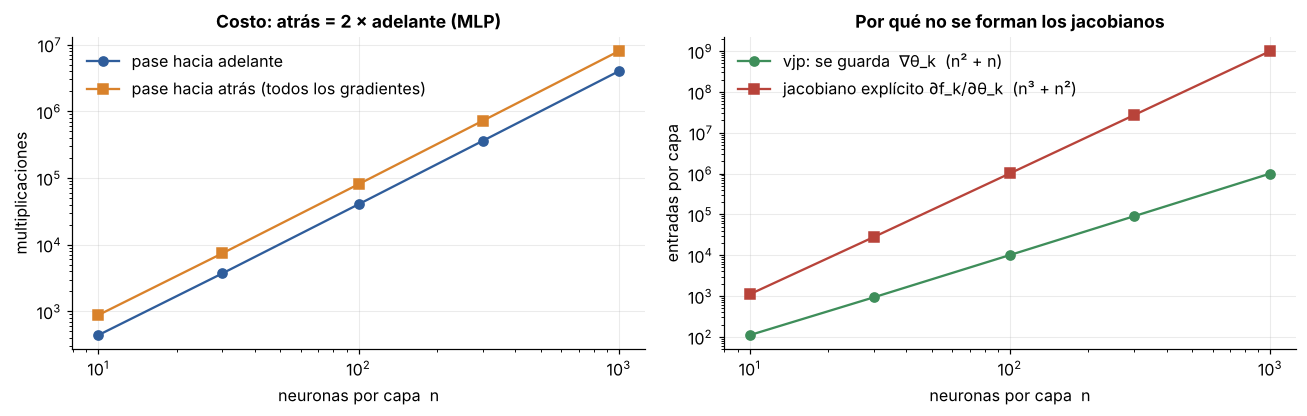

In [25]:
# ---------- Costo: pase hacia atrás vs pase hacia adelante (MLP L = 4 con n neuronas por capa) ----------
def costos_mlp(n, L_capas=4, semilla=0):
    r = np.random.default_rng(semilla)
    caps = [Densa("tanh") for _ in range(L_capas)]
    th = [(r.standard_normal((n, n)) / np.sqrt(n), np.zeros(n)) for _ in range(L_capas)]
    x = r.standard_normal(n); y = r.standard_normal(n)
    CONT["mult"] = 0; a = pase_adelante(caps, th, x); c_ad = CONT["mult"]
    CONT["mult"] = 0; pase_atras(caps, th, a, lambda z: np.tanh(z - y)); c_at = CONT["mult"]
    return c_ad, c_at

filas = []
for n in [10, 30, 100, 300, 1000]:
    c_ad, c_at = costos_mlp(n)
    # lo que costaría / ocuparía formar los jacobianos de una capa densa n→n:  ∂f/∂θ es n × (n² + n)
    filas.append(dict(n=n, mult_adelante=c_ad, mult_atras=c_at, cociente=c_at / c_ad,
                      entradas_vjp=n * n + n, entradas_jac_theta=n * (n * n + n)))
CT = pd.DataFrame(filas)
tabla(CT.rename(columns={"mult_adelante": "mult. adelante", "mult_atras": "mult. atrás", "cociente": "atrás / adelante",
                         "entradas_vjp": "|θ_k| (lo que guarda el vjp)", "entradas_jac_theta": "entradas de ∂f_k/∂θ_k"}), decimales=3)
registrar("5", "Costo atrás/adelante ≤ 2.5 (constante, independiente de n) para n = 10…1000", max(0, CT.cociente.max() - 2.5), 0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
ax[0].loglog(CT.n, CT.mult_adelante, "o-", color=C["azul"], label="pase hacia adelante")
ax[0].loglog(CT.n, CT.mult_atras, "s-", color=C["naranja"], label="pase hacia atrás (todos los gradientes)")
ax[0].set_xlabel("neuronas por capa  n"); ax[0].set_ylabel("multiplicaciones"); ax[0].legend(frameon=False)
ax[0].set_title("Costo: atrás = 2 × adelante (MLP)", fontweight="bold")
ax[1].loglog(CT.n, CT.entradas_vjp, "o-", color=C["verde"], label="vjp: se guarda  ∇θ_k  (n² + n)")
ax[1].loglog(CT.n, CT.entradas_jac_theta, "s-", color=C["rojo"], label="jacobiano explícito ∂f_k/∂θ_k  (n³ + n²)")
ax[1].set_xlabel("neuronas por capa  n"); ax[1].set_ylabel("entradas por capa"); ax[1].legend(frameon=False)
ax[1].set_title("Por qué no se forman los jacobianos", fontweight="bold")
fig.tight_layout()

**Conclusión de la sección 5.** La demostración se apoya en las funciones «cola» $F_k$: por inducción descendente $\nabla F_k(a_k)=\delta_k$ (regla de la cadena y transposición), lo que da $\nabla_{a_k}\mathcal L=\delta_k$; y como $a_{k-1}$ y $F_k$ no dependen de $\theta_k$, se obtiene $\nabla_{\theta_k}\mathcal L=(\partial f_k/\partial\theta_k)^\top\delta_k$.
Numéricamente, el esquema genérico reproduce las diferencias finitas y la cadena de jacobianos explícitos en una MLP y en una red con capa convolucional (error $\lesssim10^{-8}$). El conteo de multiplicaciones (productos matriz–vector, productos externos y operaciones elementales, medidos dentro del propio código) da un pase hacia atrás de **2 veces** el costo del pase hacia adelante en esta MLP, mientras que el jacobiano explícito $\partial f_k/\partial\theta_k$ de una capa densa tiene $\sim n^3$ entradas frente a las $\sim n^2$ del `vjp`.

---
# 6 · Lema 3.1: campo receptivo

*Fuente: Lección 3 (Convolutional Neural Networks), Lemma 3.1 y la «Consecuencia numérica» que le sigue.*

### Enunciado

> **Lemma 3.1 (Campo receptivo)**
>
> Consideremos $L$ capas convolucionales sucesivas con filtros de lado $m_1,\dots,m_L$ y *strides* $s_1,\dots,s_L$. El lado del campo receptivo (en la entrada) de una unidad de la capa $L$ es
>
> $$r_L = 1+\sum_{k=1}^{L}(m_k-1)\prod_{j=1}^{k-1}s_j .$$

### Demostración

**Paso 0 (modelo y definiciones).** Como las convoluciones 2D actúan de forma independiente en cada eje, basta razonar en **una dimensión**; el lado en 2D es el mismo en cada eje.
La capa $k$ (sin *padding*, *stride* $s_k$, filtro de lado $m_k$) produce la unidad $i$ ($i=1,2,\dots$) a partir de las $m_k$ unidades contiguas de la capa $k-1$ con índices
$$s_k(i-1)+t,\qquad t=1,\dots,m_k .$$
Las unidades de la capa $0$ son los píxeles de entrada. El **campo receptivo** $R_k(i)$ es el conjunto de píxeles de entrada de los que depende la unidad $i$ de la capa $k$: $R_0(i)=\{i\}$ y $R_k(i)=\bigcup_{t=1}^{m_k}R_{k-1}\bigl(s_k(i-1)+t\bigr)$. Su **lado** es la extensión $\max R_k(i)-\min R_k(i)+1$.
Sea $J_k=\prod_{j\le k}s_j$ con $J_0=1$: la separación, en píxeles de entrada, entre dos unidades contiguas de la capa $k$. Sea $r_k$ el lado en la capa $k$, con $r_0=1$.

**Paso 1 (afirmación por inducción).** Para todo $k\ge0$ y toda unidad $i$:
$$\min R_k(i)=J_k\,(i-1)+1,\qquad \max R_k(i)=J_k\,(i-1)+r_k,\qquad r_k=r_{k-1}+(m_k-1)J_{k-1}.$$

* *Base* $k=0$: $R_0(i)=\{i\}$, así que $\min=\max=i=J_0(i-1)+1$ y $r_0=1$. $\checkmark$
* *Paso inductivo.* Suponemos la afirmación para $k-1$. La unidad $i$ de la capa $k$ usa las unidades $i'=s_k(i-1)+t$, $t=1,\dots,m_k$, de la capa $k-1$. Por hipótesis,
  $$\min R_{k-1}(i')=J_{k-1}(i'-1)+1=J_{k-1}\,s_k(i-1)+J_{k-1}(t-1)+1=J_k(i-1)+J_{k-1}(t-1)+1,$$
  que crece con $t$. El mínimo de la unión se alcanza en $t=1$: $\min R_k(i)=J_k(i-1)+1$. $\checkmark$
  Análogamente, $\max R_{k-1}(i')=\min R_{k-1}(i')+r_{k-1}-1=J_k(i-1)+J_{k-1}(t-1)+r_{k-1}$, que también crece con $t$; el máximo se alcanza en $t=m_k$:
  $$\max R_k(i)=J_k(i-1)+J_{k-1}(m_k-1)+r_{k-1}.$$
  Por tanto el lado es
  $$r_k=\max R_k(i)-\min R_k(i)+1=J_{k-1}(m_k-1)+r_{k-1},$$
  y $\max R_k(i)=J_k(i-1)+r_k$. $\checkmark$

(Esto es la frase de la lección: una unidad de la capa $k$ combina $m_k$ unidades contiguas de la capa $k-1$, que abarcan $(m_k-1)J_{k-1}$ píxeles adicionales a los de una sola unidad.)

**Paso 2 (suma).** Desarrollando la recurrencia $r_k=r_{k-1}+(m_k-1)J_{k-1}$ desde $r_0=1$ y con $J_{k-1}=\prod_{j=1}^{k-1}s_j$:
$$r_L=r_0+\sum_{k=1}^{L}(m_k-1)J_{k-1}=1+\sum_{k=1}^{L}(m_k-1)\prod_{j=1}^{k-1}s_j.\qquad\blacksquare$$

**Observaciones.**
(i) El lado de la fórmula es la extensión del campo; si algún $J_{k-1}$ supera a $r_{k-1}$ el campo puede tener «huecos» y contiene menos píxeles que $r_L$. Ocurre, por ejemplo, con $m=(1,3)$, $s=(3,1)$: $r_2=1+0+2\cdot3=7$, pero la unidad solo depende de los píxeles $\{1,4,7\}$. Lo comprobamos abajo.
(ii) El *stride* $s_k$ no afecta a $r_k$, solo a los $J$ de las capas **siguientes**: por eso el producto llega hasta $k-1$.

### Consecuencia numérica de la lección

Con *stride* 1 y filtros $3\times3$: $J_{k-1}=1$ y $r_L=1+\sum_{k=1}^{L}2=2L+1$. Para $L=3$, $r_3=7$: tres capas $3\times3$ ven la misma región que una capa $7\times7$.
Con $C$ canales de entrada y de salida en cada capa (sin sesgos), el apilamiento usa $3\cdot(3\cdot3\cdot C^2)=27C^2$ parámetros frente a $7\cdot7\cdot C^2=49C^2$ de una sola capa $7\times7$. Para $C=64$: $27\cdot4096=110\,592$ frente a $49\cdot4096=200\,704$, un ahorro de $1-27/49\approx44.9\,\%$ (la lección dice «cercano al 45 %»).

### Verificación numérica

Para no repetir la recurrencia del propio lema, medimos el campo receptivo **de forma independiente**: construimos las capas como matrices lineales con pesos aleatorios **estrictamente positivos** (así no hay cancelaciones) y calculamos el producto de matrices $M_L\cdots M_1$; el soporte de cada fila (entradas no nulas) es exactamente el conjunto $R_L(i)$. Comparamos su mínimo, máximo y extensión con las fórmulas del Paso 1.

In [26]:
rng6 = np.random.default_rng(2026)

def campo_formula(m, s):
    """r_L = 1 + Σ_{k=1}^{L} (m_k − 1) Π_{j=1}^{k−1} s_j   (Lema 3.1)."""
    return 1 + sum((m[k] - 1) * int(np.prod(s[:k])) for k in range(len(m)))

def mat_conv1d(N, w, s):
    """Capa convolucional 1D como matriz (sin padding): unidad i lee las posiciones s·i, …, s·i + m − 1 (0-based)."""
    m = len(w); No = (N - m) // s + 1; M = np.zeros((No, N))
    for i in range(No): M[i, s * i:s * i + m] = w
    return M

def config_aleatoria(max_L=5):
    L_ = int(rng6.integers(1, max_L + 1)); m = [int(x) for x in rng6.integers(1, 8, L_)]; s = [int(x) for x in rng6.integers(1, 5, L_)]
    n_out = int(rng6.integers(1, 5)); N = [n_out]                       # tamaños hacia atrás, para que siempre haya n_out unidades en la capa L
    for k in range(L_ - 1, -1, -1): N.insert(0, s[k] * (N[0] - 1) + m[k] + int(rng6.integers(0, s[k])))
    return m, s, N                                                       # N = [N_0, …, N_L]

fallos = 0; casos = 0; comprobaciones_capa = 0
for _ in range(500):
    m, s, N = config_aleatoria()
    Ms = [mat_conv1d(N[k], rng6.uniform(0.5, 1.5, m[k]), s[k]) for k in range(len(m))]
    prod = np.eye(N[0]); J = 1
    for k in range(len(m)):                                             # k = 0..L−1  ↔  capa k+1
        prod = Ms[k] @ prod; J_k = J * s[k]
        r_medido_ref = campo_formula(m[:k + 1], s[:k + 1])
        for i in range(prod.shape[0]):
            sop = np.flatnonzero(prod[i] > 0)
            comprobaciones_capa += 1
            if not (sop.min() == J_k * i and sop.max() - sop.min() + 1 == r_medido_ref): fallos += 1
        J = J_k
    casos += 1
print(f"{casos} configuraciones aleatorias (L ≤ 5, m ≤ 7, s ≤ 4) · {comprobaciones_capa} unidades verificadas en todas las capas intermedias.")
registrar("6", "1D: mín, máx y lado del campo receptivo medidos vs fórmulas del Lema 3.1 (nº de fallos)", fallos, 0)

500 configuraciones aleatorias (L ≤ 5, m ≤ 7, s ≤ 4) · 39322 unidades verificadas en todas las capas intermedias.
✔ 1D: mín, máx y lado del campo receptivo medidos vs fórmulas del Lema 3.1 (nº de fallos)  |  error = 0.00e+00  (tolerancia 0.0e+00)


In [27]:
# ---------- 2D: filtros densos positivos (no separables); soporte = cuadrado de lado r_L ----------
def mat_conv2d(N, h, s):
    m = h.shape[0]; No = (N - m) // s + 1; M = np.zeros((No * No, N * N))
    for i in range(No):
        for j in range(No):
            for t in range(m):
                for r in range(m): M[i * No + j, (s * i + t) * N + (s * j + r)] = h[t, r]
    return M, No

fallos2 = 0; casos2 = 0
for _ in range(40):
    L_ = int(rng6.integers(1, 4)); m = [int(x) for x in rng6.integers(1, 5, L_)]; s = [int(x) for x in rng6.integers(1, 4, L_)]
    N = [2]
    for k in range(L_ - 1, -1, -1): N.insert(0, s[k] * (N[0] - 1) + m[k])
    prod = np.eye(N[0] ** 2)
    for k in range(L_):
        M, No = mat_conv2d(N[k], rng6.uniform(0.5, 1.5, (m[k], m[k])), s[k]); prod = M @ prod
    J = int(np.prod(s)); r = campo_formula(m, s)
    for i in range(No):
        for j in range(No):
            sop = np.flatnonzero(prod[i * No + j] > 0); fil, col = sop // N[0], sop % N[0]; casos2 += 1
            ok = (fil.min() == J * i and fil.max() - fil.min() + 1 == r and col.min() == J * j and col.max() - col.min() + 1 == r)
            fallos2 += (not ok)
print(f"2D: {casos2} unidades de salida verificadas en 40 configuraciones aleatorias.")
registrar("6", "2D: el campo receptivo es un cuadrado de lado r_L, anclado en J_L·(i−1)+1 (nº de fallos)", fallos2, 0)

# --- tres capas 3×3 (stride 1) vs una capa 7×7 ---
m3, s3 = [3, 3, 3], [1, 1, 1]
registrar("6", "Consecuencia: r_L = 2L + 1 con filtros 3×3 y stride 1 (L = 1,…,10)", max(abs(campo_formula([3] * L_, [1] * L_) - (2 * L_ + 1)) for L_ in range(1, 11)), 0)
registrar("6", "Tres capas 3×3 con stride 1 ven lo mismo que una capa 7×7 (r = 7)", abs(campo_formula(m3, s3) - campo_formula([7], [1])), 0)

# --- ejemplo con huecos: m = (1, 3), s = (3, 1) ---
mg, sg = [1, 3], [3, 1]; Ng = [7, 3, 1]
Mg = mat_conv1d(Ng[1], np.ones(3), 1) @ mat_conv1d(Ng[0], np.ones(1), 3)
sop = np.flatnonzero(Mg[0] > 0) + 1
print(f"Ejemplo con huecos: m={mg}, s={sg}  →  r_2 = {campo_formula(mg, sg)}; la unidad depende de los píxeles {[int(v) for v in sop]} ({len(sop)} píxeles, extensión {sop.max() - sop.min() + 1}).")
registrar("6", "Ejemplo con huecos: extensión = r_2 = 7 aunque solo 3 píxeles influyen", abs((sop.max() - sop.min() + 1) - campo_formula(mg, sg)) + abs(len(sop) - 3), 0)

# --- parámetros: apilamiento 3×(3×3) vs una 7×7, con C canales ---
par_pila = lambda C_, L_=3, m_=3: L_ * (m_ * m_ * C_ * C_)
par_unica = lambda C_, m_=7: m_ * m_ * C_ * C_
Cc = 64
print(f"C = {Cc}:  3 capas 3×3 → {par_pila(Cc):,} parámetros   |   1 capa 7×7 → {par_unica(Cc):,} parámetros   |   ahorro = {100 * (1 - par_pila(Cc) / par_unica(Cc)):.1f} %")
registrar("6", "27C² = 110 592 y 49C² = 200 704 para C = 64 (valores de la lección)", abs(par_pila(Cc) - 110592) + abs(par_unica(Cc) - 200704), 0)
registrar("6", "Ahorro 1 − 27/49 ≈ 45 % (la lección: «cercano al 45 %»)", abs(100 * (1 - 27 / 49) - 45), 0.5)

2D: 160 unidades de salida verificadas en 40 configuraciones aleatorias.
✔ 2D: el campo receptivo es un cuadrado de lado r_L, anclado en J_L·(i−1)+1 (nº de fallos)  |  error = 0.00e+00  (tolerancia 0.0e+00)
✔ Consecuencia: r_L = 2L + 1 con filtros 3×3 y stride 1 (L = 1,…,10)  |  error = 0.00e+00  (tolerancia 0.0e+00)
✔ Tres capas 3×3 con stride 1 ven lo mismo que una capa 7×7 (r = 7)  |  error = 0.00e+00  (tolerancia 0.0e+00)
Ejemplo con huecos: m=[1, 3], s=[3, 1]  →  r_2 = 7; la unidad depende de los píxeles [1, 4, 7] (3 píxeles, extensión 7).
✔ Ejemplo con huecos: extensión = r_2 = 7 aunque solo 3 píxeles influyen  |  error = 0.00e+00  (tolerancia 0.0e+00)
C = 64:  3 capas 3×3 → 110,592 parámetros   |   1 capa 7×7 → 200,704 parámetros   |   ahorro = 44.9 %
✔ 27C² = 110 592 y 49C² = 200 704 para C = 64 (valores de la lección)  |  error = 0.00e+00  (tolerancia 0.0e+00)
✔ Ahorro 1 − 27/49 ≈ 45 % (la lección: «cercano al 45 %»)  |  error = 1.02e-01  (tolerancia 5.0e-01)


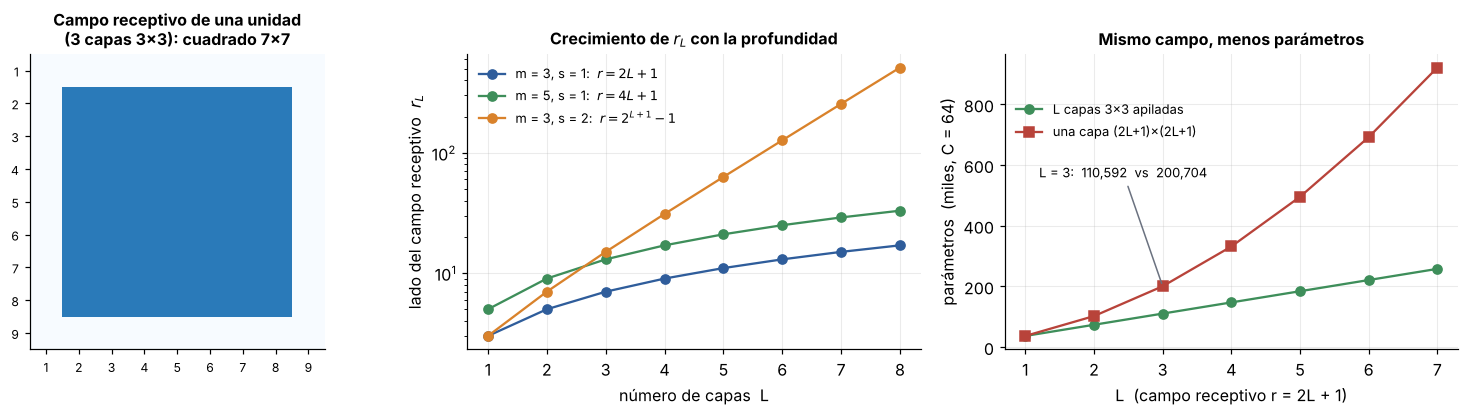

In [28]:
# ---------- Figura: campo receptivo 2D, crecimiento de r_L y costo en parámetros ----------
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), gridspec_kw=dict(width_ratios=[1, 1.1, 1.1]))

# (a) soporte de una unidad de la capa 3 (3 capas 3×3, stride 1) sobre una entrada 9×9
Nn = [9, 7, 5, 3]; prod = np.eye(81)
for k in range(3):
    M, _ = mat_conv2d(Nn[k], rng6.uniform(0.5, 1.5, (3, 3)), 1); prod = M @ prod
sop2d = (prod[4] > 0).reshape(9, 9)                                     # unidad central de la capa 3 (3×3)
ax[0].imshow(sop2d, cmap="Blues", vmin=0, vmax=1.4); ax[0].grid(False)
ax[0].set_xticks(range(9)); ax[0].set_yticks(range(9)); ax[0].set_xticklabels(range(1, 10), fontsize=8); ax[0].set_yticklabels(range(1, 10), fontsize=8)
ax[0].set_title("Campo receptivo de una unidad\n(3 capas 3×3): cuadrado 7×7", fontsize=10.5, fontweight="bold")

# (b) r_L vs L
Ls = np.arange(1, 9)
for (mm, ss, col, et) in [(3, 1, C["azul"], r"m = 3, s = 1:  $r = 2L+1$"), (5, 1, C["verde"], r"m = 5, s = 1:  $r = 4L+1$"), (3, 2, C["naranja"], r"m = 3, s = 2:  $r = 2^{L+1}-1$")]:
    ax[1].plot(Ls, [campo_formula([mm] * l_, [ss] * l_) for l_ in Ls], "o-", color=col, label=et)
ax[1].set_yscale("log"); ax[1].set_xlabel("número de capas  L"); ax[1].set_ylabel(r"lado del campo receptivo  $r_L$")
ax[1].set_title(r"Crecimiento de $r_L$ con la profundidad", fontsize=10.5, fontweight="bold"); ax[1].legend(frameon=False, fontsize=8.5)

# (c) parámetros para un mismo campo receptivo r = 2L+1
Ls2 = np.arange(1, 8)
ax[2].plot(Ls2, [par_pila(64, l_) / 1e3 for l_ in Ls2], "o-", color=C["verde"], label="L capas 3×3 apiladas")
ax[2].plot(Ls2, [par_unica(64, 2 * l_ + 1) / 1e3 for l_ in Ls2], "s-", color=C["rojo"], label="una capa (2L+1)×(2L+1)")
for l_ in [3]:
    ax[2].annotate(f"L = 3:  {par_pila(64, 3):,}  vs  {par_unica(64):,}", xy=(l_, par_unica(64) / 1e3), xytext=(1.2, 560), fontsize=8.5, arrowprops=dict(arrowstyle="-", color=C["gris"]))
ax[2].set_xlabel("L  (campo receptivo r = 2L + 1)"); ax[2].set_ylabel("parámetros  (miles, C = 64)")
ax[2].set_title("Mismo campo, menos parámetros", fontsize=10.5, fontweight="bold"); ax[2].legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(0, 0.88))
fig.tight_layout()

**Conclusión de la sección 6.** Por inducción sobre las capas se prueba que la unidad $i$ de la capa $k$ depende de los píxeles entre $J_k(i-1)+1$ y $J_k(i-1)+r_k$, con $r_k=r_{k-1}+(m_k-1)J_{k-1}$; sumando se obtiene $r_L=1+\sum_{k=1}^{L}(m_k-1)\prod_{j<k}s_j$.
La medición independiente (producto de matrices positivas) coincide con la fórmula en 500 configuraciones 1D y 40 configuraciones 2D, sin ningún fallo. Se reproducen también los números de la lección: $r_L=2L+1$ con filtros $3\times3$, $r_3=7$ y $27C^2=110\,592$ frente a $49C^2=200\,704$ parámetros para $C=64$ (ahorro $\approx44.9\,\%$).

---
# 7 · Teorema 3.4: beneficio de la profundidad

*Fuente: Lección 3 (Convolutional Neural Networks), Theorem 3.4, a continuación del Lema 3.1.*

### Enunciado

> **Theorem 3.4 (Beneficio de la profundidad)**
>
> Sea $m(x)=2\,\mathrm{ReLU}(x)-4\,\mathrm{ReLU}\bigl(x-\tfrac12\bigr)$, que sobre $[0,1]$ es la función «tienda» ($m(x)=2x$ si $x\le\tfrac12$ y $m(x)=2-2x$ si $x\ge\tfrac12$). Para todo $k\ge1$:
>
> 1. La función $m^{\circ k}$ (composición $k$ veces) es calculada exactamente sobre $[0,1]$ por una red ReLU con $k$ capas ocultas de ancho 2.
> 2. $m^{\circ k}$ tiene $2^k$ tramos lineales.
> 3. Toda red ReLU de una sola capa oculta que coincida con $m^{\circ k}$ en $[0,1]$ necesita al menos $2^k-1$ neuronas.

### Demostración

**Paso 0 (hechos previos).**
*Tramos lineales.* $f:[0,1]\to\mathbb R$ tiene $N$ tramos si existen $0=x_0<x_1<\dots<x_N=1$ con $f$ afín en cada $[x_{j-1},x_j]$ y pendientes consecutivas distintas. Los $x_1,\dots,x_{N-1}$ son los **puntos de quiebre**: los puntos interiores en cuyo entorno $f$ no es afín. Luego #tramos = #quiebres + 1.
*$m$ por ramas.* Para $x\in[0,1]$, $\mathrm{ReLU}(x)=x$; y $\mathrm{ReLU}(x-\tfrac12)=0$ si $x\le\tfrac12$ y $=x-\tfrac12$ si $x\ge\tfrac12$. Así
$$x\le\tfrac12:\ m(x)=2x,\qquad x\ge\tfrac12:\ m(x)=2x-4\bigl(x-\tfrac12\bigr)=2-2x .$$
*Imagen.* $m(0)=0$, $m(\tfrac12)=1$, $m(1)=0$, y $m$ es afín creciente en $[0,\tfrac12]$ y afín decreciente en $[\tfrac12,1]$; por tanto $m([0,1])=[0,1]$ y $m^{\circ k}$ está bien definida en $[0,1]$ para todo $k$.

**Paso 1 (prueba de (1): la red).**

* *(1a) Una capa calcula $m$.* Para $y\in[0,1]$, una capa oculta con neuronas $h_1=\mathrm{ReLU}(y)$ y $h_2=\mathrm{ReLU}(y-\tfrac12)$ (pesos de entrada $(1,1)$, sesgos $(0,-\tfrac12)$) y salida $2h_1-4h_2$ da exactamente $m(y)$ (Paso 0).
* *(1b) Apilar $k$ capas.* Sea $y_0=x$ y $y_r=m(y_{r-1})=2h_1^{(r-1)}-4h_2^{(r-1)}$. La capa oculta $r$ necesita las preactivaciones $y_{r-1}$ e $y_{r-1}-\tfrac12$, que son **combinaciones afines** de las dos activaciones de la capa $r-1$: $y_{r-1}=2h_1^{(r-1)}-4h_2^{(r-1)}$. Esa es justamente la forma de una red completamente conectada: pesos $\begin{pmatrix}2&-4\\2&-4\end{pmatrix}$ y sesgos $(0,-\tfrac12)$ entre capas ocultas consecutivas.
* *(1c) Valor exacto.* Por inducción, $y_r=m^{\circ r}(x)$: para $r=1$ es (1a); si $y_{r-1}=m^{\circ(r-1)}(x)$ entonces $y_r=m(y_{r-1})=m^{\circ r}(x)$. Como $y_{r-1}\in[0,1]$ (por el Paso 0), son válidas la identidad $\mathrm{ReLU}(y)=y$ y la expresión de $m$ en cada capa. (Fuera de $[0,1]$ la red no calcula $m$: por eso el enunciado se restringe a $[0,1]$.)
* *(1d) Conteo.* La salida lineal $2h_1^{(k)}-4h_2^{(k)}=y_k=m^{\circ k}(x)$. Hay $k$ capas ocultas de ancho 2, es decir, $2k$ neuronas. $\checkmark$

**Paso 2 (prueba de (2): estructura exacta de $m^{\circ k}$).** Contar tramos no basta para la inducción; se prueba algo más fuerte.

> **Afirmación $Q(k)$.** Sea $I_j^k=\bigl[\tfrac{j-1}{2^k},\tfrac{j}{2^k}\bigr]$, $j=1,\dots,2^k$. En cada $I_j^k$, $m^{\circ k}$ es afín y aplica $I_j^k$ **sobre** $[0,1]$ con pendiente $+2^k$ si $j$ es impar y $-2^k$ si $j$ es par (crece de 0 a 1 si $j$ es impar y decrece de 1 a 0 si $j$ es par).

* *(2a) Base $k=1$.* $I_1^1=[0,\tfrac12]$, $I_2^1=[\tfrac12,1]$: por el Paso 0, $m$ crece de 0 a 1 con pendiente $2$ y luego decrece de 1 a 0 con pendiente $-2$. $\checkmark$
* *(2b) Paso inductivo.* Suponemos $Q(k)$ y escribimos $m^{\circ(k+1)}=m\circ m^{\circ k}$. Fijamos $j$ y sea $\varphi=m^{\circ k}|_{I_j^k}$, biyección afín de $I_j^k$ sobre $[0,1]$ con pendiente $\sigma=\pm2^k$. Como $\varphi$ es afín y biyectiva, lleva el punto medio de $I_j^k$ a $\tfrac12$. Sean $J_-=I_{2j-1}^{k+1}$ y $J_+=I_{2j}^{k+1}$ las mitades izquierda y derecha de $I_j^k$.
  * *$j$ impar* ($\sigma=+2^k$, $\varphi$ creciente): $\varphi(J_-)=[0,\tfrac12]$ y $\varphi(J_+)=[\tfrac12,1]$. En $J_-$, $m(y)=2y$: $m\circ\varphi$ crece de $m(0)=0$ a $m(\tfrac12)=1$ con pendiente $2\sigma=+2^{k+1}$. En $J_+$, $m(y)=2-2y$: decrece de $m(\tfrac12)=1$ a $m(1)=0$ con pendiente $-2\sigma=-2^{k+1}$.
  * *$j$ par* ($\sigma=-2^k$, $\varphi$ decreciente): $\varphi(J_-)=[\tfrac12,1]$ (recorrido de 1 a $\tfrac12$) y $\varphi(J_+)=[0,\tfrac12]$ (de $\tfrac12$ a 0). En $J_-$, $m(y)=2-2y$: $m\circ\varphi$ va de $m(1)=0$ a $m(\tfrac12)=1$ con pendiente $(-2)(-2^k)=+2^{k+1}$. En $J_+$, $m(y)=2y$: va de 1 a 0 con pendiente $2\cdot(-2^k)=-2^{k+1}$.

  La composición de afines es afín y las pendientes se multiplican; $\varphi$ cae en una sola rama de $m$ en cada mitad (por eso se parte $I_j^k$ por el punto medio). En ambos casos $J_-=I_{2j-1}^{k+1}$ (índice impar) tiene pendiente $+2^{k+1}$ y $J_+=I_{2j}^{k+1}$ (índice par) pendiente $-2^{k+1}$, y ambos se aplican **sobre** $[0,1]$. Como $j$ recorre $1,\dots,2^k$, se cubren los $2^{k+1}$ intervalos: $Q(k+1)$. $\checkmark$
* *(2c) Número de tramos.* Por $Q(k)$, $m^{\circ k}$ es afín en cada uno de los $2^k$ intervalos y las pendientes consecutivas son $+2^k$ y $-2^k$, distintas. Por tanto $m^{\circ k}$ tiene **exactamente $2^k$ tramos lineales**, con puntos de quiebre en $j/2^k$, $j=1,\dots,2^k-1$ (esto es, $2^k-1$ puntos en $(0,1)$). Coincide con la recursión $1\to2\to4\to\cdots\to2^k$.

**Paso 3 (prueba de (3): cota inferior para una capa oculta).**

* *(3a) Forma.* Una red ReLU con una capa oculta de $N$ neuronas y salida escalar es $f(x)=d+\sum_{i=1}^{N}c_i\,\mathrm{ReLU}(w_ix+b_i)$.
* *(3b) Cada neurona aporta a lo sumo un quiebre.* Si $w_i=0$, $\mathrm{ReLU}(b_i)$ es constante. Si $w_i\ne0$, $\mathrm{ReLU}(w_ix+b_i)$ es afín a cada lado de $p_i=-b_i/w_i$ y solo puede dejar de ser afín en $p_i$.
* *(3c) Dónde puede quebrarse $f$.* Sea $P=\{p_i: w_i\neq0\}$, con $|P|\le N$. En cualquier intervalo abierto sin puntos de $P$ cada sumando es afín, luego $f$ es afín. Así, todo punto de quiebre de $f$ pertenece a $P$.
* *(3d) Comparación con $m^{\circ k}$.* Supongamos $f=m^{\circ k}$ en $[0,1]$ y sea $x_0=j/2^k$ con $1\le j\le2^k-1$. Por el Paso 2, $m^{\circ k}$ tiene pendientes distintas a ambos lados de $x_0$, así que no es afín en ningún entorno de $x_0$. Como $x_0\in(0,1)$, hay un entorno abierto de $x_0$ dentro de $[0,1]$ donde $f=m^{\circ k}$; luego $f$ tampoco es afín en ningún entorno de $x_0$ y, por (3c), $x_0\in P$.
* *(3e) Conteo.* Los $2^k-1$ puntos $j/2^k$ son distintos y todos están en $P$: $\;N\ge|P|\ge2^k-1$. $\checkmark$

**Paso 4 (cierre).** Por (1), la profundidad $k$ con ancho 2 usa $2k$ neuronas; por (3), una sola capa oculta necesita al menos $2^k-1$. Con $k=10$: $20$ neuronas frente a $\ge1023$. $\blacksquare$

**Complemento (no pedido en el enunciado; lo añadimos porque cierra el resultado).** La cota $2^k-1$ puede mejorarse a **exactamente $2^k$**, y $2^k$ neuronas bastan:

* *Construcción con $2^k$ neuronas.* Como $m^{\circ k}$ es lineal a trozos con $m^{\circ k}(0)=0$, pendiente inicial $2^k$ y saltos de pendiente $\Delta_j=(-1)^j2^{k+1}$ en $j/2^k$ (de $(-1)^{j-1}2^k$ a $(-1)^j2^k$), entonces sobre $[0,1]$
  $$m^{\circ k}(x)=2^k\,\mathrm{ReLU}(x)+\sum_{j=1}^{2^k-1}(-1)^j\,2^{k+1}\,\mathrm{ReLU}\!\Bigl(x-\frac{j}{2^k}\Bigr).$$
* *$2^k-1$ neuronas no alcanzan.* Si $N=2^k-1$, por (3) cada neurona tiene su quiebre en un $j/2^k$ distinto. Escribimos $\mathrm{ReLU}(w x+b)=|w|\,\mathrm{ReLU}\bigl(s(x-p)\bigr)$ con $s=\operatorname{sign}w$ y usamos $\mathrm{ReLU}(-t)=\mathrm{ReLU}(t)-t$: entonces $f(x)=d'+\beta x+\sum_ia_i\mathrm{ReLU}(x-p_i)$, donde $a_i=c_i|w_i|$ es el salto de pendiente en $p_i$ y $\beta=-\sum_{i:\,s_i=-1}a_i$ es la pendiente en $0^+$. Igualando con $m^{\circ k}$: $a_i=\Delta_{j(i)}$ y $\beta=2^k$. Pero entonces $2^k=-2^{k+1}\sum_{j\in S}(-1)^j$ para algún subconjunto $S$, es decir, un entero igual a $\tfrac12$: imposible. Por tanto el mínimo exacto es $2^k$ (para $k=1$: $2$ neuronas, las de $m$).

### Verificación numérica

1. **(1)** Construimos la red de $k$ capas ocultas de ancho 2 con los pesos del Paso 1 y la comparamos con una referencia **independiente**: la onda triangular $2\,\mathrm{dist}(2^{k-1}x,\mathbb Z)$ (equivalente a $Q(k)$; solo se usa como referencia, no en la prueba). En una malla diádica la aritmética en coma flotante es exacta.
2. **(2)** A partir de la salida de la red contamos tramos y quiebres, y comprobamos pendientes $\pm2^k$ alternadas y los valores $m^{\circ k}(j/2^k)\in\{0,1\}$.
3. **(3)** Verificamos el conteo de quiebres de redes de una capa oculta aleatorias (a lo sumo $N$), la construcción con $2^k$ neuronas, y, para $k=1,2,3$, que con $2^k-1$ neuronas colocadas en los quiebres correctos y **cualquier** orientación no se puede ajustar (complemento).

In [29]:
relu = lambda z: np.maximum(z, 0.0)

def red_profunda(k):
    """k capas ocultas de ancho 2 (pesos del Paso 1) + salida lineal (2, −4)."""
    capas = [(np.array([[1.0], [1.0]]), np.array([0.0, -0.5]))]
    capas += [(np.array([[2.0, -4.0], [2.0, -4.0]]), np.array([0.0, -0.5])) for _ in range(k - 1)]
    return capas, np.array([2.0, -4.0])

def evaluar_red(capas, v, x):
    a = np.atleast_1d(x)[None, :]                         # (1, n)
    for W_, b_ in capas: a = relu(W_ @ a + b_[:, None])    # (2, n)
    return v @ a                                          # (n,)

onda = lambda k, x: 2 * np.abs(2 ** (k - 1) * x - np.round(2 ** (k - 1) * x))   # 2·dist(2^{k−1}x, ℤ): referencia independiente
m_tienda = lambda x: 2 * relu(x) - 4 * relu(x - 0.5)

# (0) m por ramas y m([0,1]) = [0,1]
xx = np.linspace(0, 1, 100001)
registrar("7", "Paso 0: m(x) = 2x (x ≤ 1/2) y 2 − 2x (x ≥ 1/2); m([0,1]) = [0,1]", np.abs(m_tienda(xx) - np.where(xx <= 0.5, 2 * xx, 2 - 2 * xx)).max() + abs(m_tienda(xx).min()) + abs(m_tienda(xx).max() - 1), 1e-12)

# (1) red de k capas ocultas de ancho 2 = m^{∘k} sobre [0,1]
rng7 = np.random.default_rng(7)
filas = []
for k in range(1, 13):
    capas, v = red_profunda(k); g = k + 4
    malla = np.arange(2 ** g + 1) / 2 ** g                                 # malla diádica: aritmética exacta
    e_exacto = np.abs(evaluar_red(capas, v, malla) - onda(k, malla)).max()
    # referencia 2: iterar m directamente k veces (con la fórmula por ramas)
    z = malla.copy()
    for _ in range(k): z = np.where(z <= 0.5, 2 * z, 2 - 2 * z)
    e_iter = np.abs(evaluar_red(capas, v, malla) - z).max()
    xr = rng7.uniform(0, 1, 2000); e_rand = np.abs(evaluar_red(capas, v, xr) - onda(k, xr)).max()
    filas.append(dict(k=k, capas_ocultas=k, neuronas=2 * k, err_malla_diadica=e_exacto, err_iterando_m=e_iter, err_puntos_aleatorios=e_rand))
T1 = pd.DataFrame(filas)
tabla(T1.rename(columns={"capas_ocultas": "capas ocultas", "neuronas": "neuronas (2k)", "err_malla_diadica": "error malla diádica", "err_iterando_m": "error vs iterar m", "err_puntos_aleatorios": "error 2000 pts aleat."}), decimales=3)
registrar("7", "(1) Red de k capas ocultas de ancho 2 = m^{∘k} en malla diádica (k = 1…12)", T1.err_malla_diadica.max(), 1e-12)
registrar("7", "(1) Red vs iterar m k veces (k = 1…12)", T1.err_iterando_m.max(), 1e-12)
registrar("7", "(1) Red vs m^{∘k} en 2000 puntos aleatorios (k = 1…12)", T1.err_puntos_aleatorios.max(), 1e-9)

✔ Paso 0: m(x) = 2x (x ≤ 1/2) y 2 − 2x (x ≥ 1/2); m([0,1]) = [0,1]  |  error = 0.00e+00  (tolerancia 1.0e-12)
✔ (1) Red de k capas ocultas de ancho 2 = m^{∘k} en malla diádica (k = 1…12)  |  error = 0.00e+00  (tolerancia 1.0e-12)
✔ (1) Red vs iterar m k veces (k = 1…12)  |  error = 0.00e+00  (tolerancia 1.0e-12)
✔ (1) Red vs m^{∘k} en 2000 puntos aleatorios (k = 1…12)  |  error = 0.00e+00  (tolerancia 1.0e-09)


k,capas ocultas,neuronas (2k),error malla diádica,error vs iterar m,error 2000 pts aleat.
1,1,2,0.000,0.000,0.000
2,2,4,0.000,0.000,0.000
3,3,6,0.000,0.000,0.000
4,4,8,0.000,0.000,0.000
5,5,10,0.000,0.000,0.000
6,6,12,0.000,0.000,0.000
7,7,14,0.000,0.000,0.000
8,8,16,0.000,0.000,0.000
9,9,18,0.000,0.000,0.000
10,10,20,0.000,0.000,0.000


In [30]:
# (2) tramos lineales, quiebres y pendientes de m^{∘k}, medidos sobre la salida de la red
filas = []; err_tramos = 0; err_quiebres = 0; err_pend = 0; err_valores = 0
for k in range(1, 11):
    capas, v = red_profunda(k); g = k + 3; n = 2 ** g
    malla = np.arange(n + 1) / n; y = evaluar_red(capas, v, malla)
    pend = np.diff(y) * n                                                # pendiente en cada celda de la malla (exacta)
    cambios = np.flatnonzero(pend[1:] != pend[:-1]) + 1                  # celdas donde cambia la pendiente
    quiebres = malla[cambios]; tramos = len(cambios) + 1
    pend_tramos = pend[np.r_[0, cambios]]                                # pendiente de cada tramo
    err_tramos += abs(tramos - 2 ** k)
    err_quiebres += np.abs(quiebres - np.arange(1, 2 ** k) / 2 ** k).max() if k > 0 and len(quiebres) == 2 ** k - 1 else 1
    err_pend += np.abs(pend_tramos - 2.0 ** k * (-1.0) ** np.arange(2 ** k)).max()      # +2^k, −2^k, +2^k, …
    nodos = np.arange(2 ** k + 1) / 2 ** k
    err_valores += np.abs(evaluar_red(capas, v, nodos) - (np.arange(2 ** k + 1) % 2)).max()   # m^{∘k}(j/2^k) = 0 (j par), 1 (j impar)
    filas.append(dict(k=k, tramos_medidos=tramos, tramos_teoria=2 ** k, quiebres=len(quiebres), pendiente_inicial=pend_tramos[0], pendiente_ultima=pend_tramos[-1]))
tabla(pd.DataFrame(filas).rename(columns={"tramos_medidos": "tramos medidos", "tramos_teoria": "2^k", "quiebres": "quiebres en (0,1)", "pendiente_inicial": "pendiente 1.er tramo", "pendiente_ultima": "pendiente último tramo"}), decimales=0)
registrar("7", "(2) Número de tramos lineales = 2^k (k = 1…10)", err_tramos, 0)
registrar("7", "(2) Puntos de quiebre en j/2^k, j = 1,…,2^k − 1", err_quiebres, 0)
registrar("7", "(2) Pendientes alternadas +2^k, −2^k, … (Q(k))", err_pend, 0)
registrar("7", "(2) m^{∘k}(j/2^k) = 0 si j par, 1 si j impar (Q(k): cada tramo aplica sobre [0,1])", err_valores, 0)

✔ (2) Número de tramos lineales = 2^k (k = 1…10)  |  error = 0.00e+00  (tolerancia 0.0e+00)
✔ (2) Puntos de quiebre en j/2^k, j = 1,…,2^k − 1  |  error = 0.00e+00  (tolerancia 0.0e+00)
✔ (2) Pendientes alternadas +2^k, −2^k, … (Q(k))  |  error = 0.00e+00  (tolerancia 0.0e+00)
✔ (2) m^{∘k}(j/2^k) = 0 si j par, 1 si j impar (Q(k): cada tramo aplica sobre [0,1])  |  error = 0.00e+00  (tolerancia 0.0e+00)


k,tramos medidos,2^k,"quiebres en (0,1)",pendiente 1.er tramo,pendiente último tramo
1,2,2,1,2,-2
2,4,4,3,4,-4
3,8,8,7,8,-8
4,16,16,15,16,-16
5,32,32,31,32,-32
6,64,64,63,64,-64
7,128,128,127,128,-128
8,256,256,255,256,-256
9,512,512,511,512,-512
10,1024,1024,1023,1024,-1024


In [31]:
# (3) una capa oculta: (a) a lo sumo N quiebres; (b) construcción con 2^k neuronas; (c) 2^k − 1 neuronas no alcanzan
def tramos_exactos(w, b, c):
    """Nº de tramos de f(x) = d + Σ c_i ReLU(w_i x + b_i) en [0,1], calculado analíticamente (pendientes exactas entre quiebres)."""
    p = np.unique(np.round([-bi / wi for wi, bi in zip(w, b) if wi != 0 and 0 < -bi / wi < 1], 12))
    cortes = np.r_[0.0, p, 1.0]; medios = (cortes[:-1] + cortes[1:]) / 2
    pend = np.array([np.sum(c * w * ((w * x + b) > 0)) for x in medios])                       # pendiente de f en cada intervalo
    return int(1 + np.sum(np.abs(np.diff(pend)) > 1e-9))

peor_exceso = 0
for N in range(1, 13):
    for _ in range(300):
        w = rng7.standard_normal(N); b = rng7.standard_normal(N) * 0.7; c = rng7.standard_normal(N)
        peor_exceso = max(peor_exceso, tramos_exactos(w, b, c) - (N + 1))
registrar("7", "(3b-c) Red de una capa oculta con N neuronas: nº de tramos ≤ N + 1 (3600 redes, N = 1…12)", peor_exceso, 0)

def red_somera(k):
    """Construcción del complemento: m^{∘k} = 2^k ReLU(x) + Σ_{j=1}^{2^k−1} (−1)^j 2^{k+1} ReLU(x − j/2^k)  (2^k neuronas)."""
    j = np.arange(2 ** k); w = np.ones(2 ** k); b = -j / 2 ** k
    c = np.where(j == 0, 2.0 ** k, (-1.0) ** j * 2.0 ** (k + 1)); return w, b, c

filas = []; err_somera = 0
for k in range(1, 11):
    w, b, c = red_somera(k); g = k + 4; malla = np.arange(2 ** g + 1) / 2 ** g
    f = (relu(np.outer(malla, w) + b) @ c)
    e = np.abs(f - onda(k, malla)).max()
    err_somera = max(err_somera, e)
    filas.append({"k": k, "profunda: 2k": 2 * k, "una capa, cota inferior 2^k − 1": 2 ** k - 1, "una capa, construcción 2^k": 2 ** k, "cociente (2^k)/(2k)": 2 ** k / (2 * k)})
T3 = pd.DataFrame(filas); tabla(T3, decimales=1)
registrar("7", "(3) La construcción con 2^k neuronas reproduce m^{∘k} en [0,1] (k = 1…10)", err_somera, 1e-9)
registrar("7", "Cifras de la lección: k = 10 → 20 neuronas (profunda) vs ≥ 1023 (una capa)", abs(T3.loc[9, "profunda: 2k"] - 20) + abs(T3.loc[9, "una capa, cota inferior 2^k − 1"] - 1023), 0)

# (c) con N = 2^k − 1 neuronas y quiebres forzados en j/2^k, probamos TODAS las orientaciones s_i = ±1 (k = 1, 2, 3)
import itertools
mejor = {}
for k in range(1, 4):
    P = np.arange(1, 2 ** k) / 2 ** k; malla = np.linspace(0, 1, 2 ** (k + 4) + 1); objetivo = onda(k, malla); mejor[k] = np.inf
    for s in itertools.product([1.0, -1.0], repeat=len(P)):
        A = np.column_stack([np.ones_like(malla)] + [relu(si * (malla - pi)) for si, pi in zip(s, P)])       # d + Σ a_i ReLU(s_i (x − p_i))
        sol = np.linalg.lstsq(A, objetivo, rcond=None)[0]; mejor[k] = min(mejor[k], np.sqrt(np.mean((A @ sol - objetivo) ** 2)))
    print(f"k = {k}:  {2 ** len(P)} orientaciones con N = {len(P)} = 2^k − 1 neurona(s);  menor error RMS alcanzable = {mejor[k]:.4f}  (la construcción con 2^k neuronas da ~1e-16)")
registrar("7", "Complemento: con 2^k − 1 neuronas ninguna orientación ajusta m^{∘k} (RMS mínimo > 1e-3, k = 1,2,3)", max(0, 1e-3 - min(mejor.values())), 0)

✔ (3b-c) Red de una capa oculta con N neuronas: nº de tramos ≤ N + 1 (3600 redes, N = 1…12)  |  error = 0.00e+00  (tolerancia 0.0e+00)
✔ (3) La construcción con 2^k neuronas reproduce m^{∘k} en [0,1] (k = 1…10)  |  error = 0.00e+00  (tolerancia 1.0e-09)
✔ Cifras de la lección: k = 10 → 20 neuronas (profunda) vs ≥ 1023 (una capa)  |  error = 0.00e+00  (tolerancia 0.0e+00)
k = 1:  2 orientaciones con N = 1 = 2^k − 1 neurona(s);  menor error RMS alcanzable = 0.2664  (la construcción con 2^k neuronas da ~1e-16)
k = 2:  8 orientaciones con N = 3 = 2^k − 1 neurona(s);  menor error RMS alcanzable = 0.1056  (la construcción con 2^k neuronas da ~1e-16)
k = 3:  128 orientaciones con N = 7 = 2^k − 1 neurona(s);  menor error RMS alcanzable = 0.0426  (la construcción con 2^k neuronas da ~1e-16)
✔ Complemento: con 2^k − 1 neuronas ninguna orientación ajusta m^{∘k} (RMS mínimo > 1e-3, k = 1,2,3)  |  error = 0.00e+00  (tolerancia 0.0e+00)


k,profunda: 2k,"una capa, cota inferior 2^k − 1","una capa, construcción 2^k",cociente (2^k)/(2k)
1,2,1,2,1.0
2,4,3,4,1.0
3,6,7,8,1.3
4,8,15,16,2.0
5,10,31,32,3.2
6,12,63,64,5.3
7,14,127,128,9.1
8,16,255,256,16.0
9,18,511,512,28.4
10,20,1023,1024,51.2


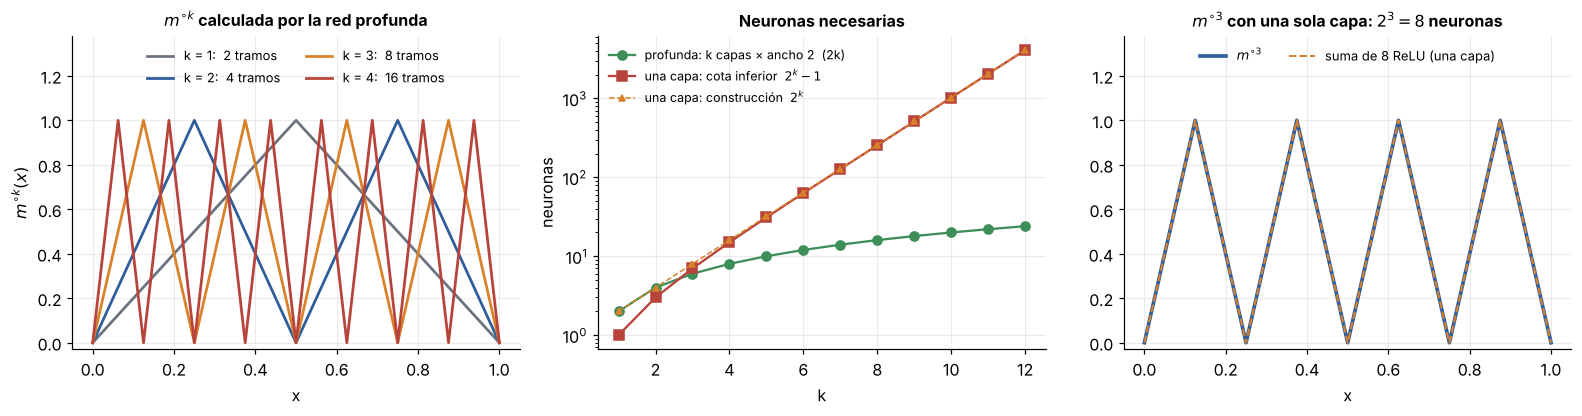

In [32]:
# ---------- Figura ----------
fig, ax = plt.subplots(1, 3, figsize=(14.5, 3.9))
xf = np.linspace(0, 1, 2001)
for k, col in zip(range(1, 5), [C["gris"], C["azul"], C["naranja"], C["rojo"]]):
    capas, v = red_profunda(k); ax[0].plot(xf, evaluar_red(capas, v, xf), color=col, lw=1.8, label=f"k = {k}:  {2 ** k} tramos")
ax[0].set_title(r"$m^{\circ k}$ calculada por la red profunda", fontsize=10.5, fontweight="bold"); ax[0].set_xlabel("x"); ax[0].set_ylabel(r"$m^{\circ k}(x)$"); ax[0].set_ylim(-0.03, 1.38); ax[0].legend(frameon=False, fontsize=8.5, loc="upper center", ncol=2)

ks = np.arange(1, 13)
ax[1].semilogy(ks, 2 * ks, "o-", color=C["verde"], label="profunda: k capas × ancho 2  (2k)")
ax[1].semilogy(ks, 2.0 ** ks - 1, "s-", color=C["rojo"], label=r"una capa: cota inferior  $2^k-1$")
ax[1].semilogy(ks, 2.0 ** ks, "^--", color=C["naranja"], ms=4, lw=1, label=r"una capa: construcción  $2^k$")
ax[1].set_title("Neuronas necesarias", fontsize=10.5, fontweight="bold"); ax[1].set_xlabel("k"); ax[1].set_ylabel("neuronas"); ax[1].legend(frameon=False, fontsize=8.2, loc="upper left")

w, b, c = red_somera(3); xg = np.linspace(0, 1, 801)
ax[2].plot(xg, onda(3, xg), color=C["azul"], lw=2.4, label=r"$m^{\circ3}$")
ax[2].plot(xg, relu(np.outer(xg, w) + b) @ c, "--", color=C["naranja"], lw=1.3, label="suma de 8 ReLU (una capa)")
ax[2].set_title(r"$m^{\circ3}$ con una sola capa: $2^3=8$ neuronas", fontsize=10.5, fontweight="bold"); ax[2].set_xlabel("x"); ax[2].set_ylim(-0.03, 1.38); ax[2].legend(frameon=False, fontsize=8.5, loc="upper center", ncol=2)
fig.tight_layout()

**Conclusión de la sección 7.** (1) Cada capa de ancho 2 aplica $m$ porque $y_{r-1}$ es afín en las activaciones anteriores; apilando $k$ capas se obtiene $m^{\circ k}$ con $2k$ neuronas. (2) Por la afirmación $Q(k)$ (pendientes $\pm2^k$, cada tramo aplicado sobre $[0,1]$) hay exactamente $2^k$ tramos y quiebres en $j/2^k$. (3) Una neurona ReLU solo puede quebrar $f$ en un punto, y $m^{\circ k}$ tiene $2^k-1$ quiebres en $(0,1)$, luego $N\ge2^k-1$.
La red profunda coincide con $m^{\circ k}$ de forma exacta en una malla diádica ($k=1,\dots,12$), los conteos de tramos y pendientes coinciden con la prueba, y para $k=10$ se reproducen las cifras de la lección: $20$ neuronas frente a $\ge1023$. Como complemento, el mínimo exacto para una capa oculta es $2^k$.

---
# 8 · Resumen de verificaciones, observaciones y conclusiones

## 8.1 Tabla de verificaciones

Cada comprobación numérica de las secciones anteriores se registró con su error y su tolerancia. La tabla se genera a partir de ese registro: si alguna fallara, la celda correspondiente habría detenido la ejecución con un error.

In [33]:
nombres = {"1": "1 · Ejercicio 2.7 (gradiente descendente)", "2": "2 · Derivada de la sigmoide (2.9)", "3": "3 · Paso del gradiente (Ejercicio 2.1)",
           "4": "4 · Proposición 3.1 (capa convolucional)", "5": "5 · Teorema 3.3 (retropropagación)", "6": "6 · Lema 3.1 (campo receptivo)", "7": "7 · Teorema 3.4 (profundidad)"}
dfv = pd.DataFrame(VERIF)
res = (dfv.groupby("seccion").agg(comprobaciones=("ok", "size"), superadas=("ok", "sum"), error_maximo=("error", "max")).reset_index())
res["Sección"] = res.seccion.map(nombres); res["Estado"] = np.where(res.superadas == res.comprobaciones, "✔ todas superadas", "✘ hay fallos")
res["Error máximo"] = res.error_maximo.map(lambda e: f"{e:.1e}")
tabla(res[["Sección", "comprobaciones", "superadas", "Error máximo", "Estado"]].rename(columns={"comprobaciones": "comprobaciones", "superadas": "superadas"}))
print(f"Total: {int(dfv.ok.sum())} de {len(dfv)} comprobaciones superadas.")
assert dfv.ok.all(), "Alguna verificación falló"

Total: 53 de 53 comprobaciones superadas.


Sección,comprobaciones,superadas,Error máximo,Estado
1 · Ejercicio 2.7 (gradiente descendente),7,7,2.0e-03,✔ todas superadas
2 · Derivada de la sigmoide (2.9),3,3,1.4e-10,✔ todas superadas
3 · Paso del gradiente (Ejercicio 2.1),7,7,2.5e-04,✔ todas superadas
4 · Proposición 3.1 (capa convolucional),7,7,7.6e-08,✔ todas superadas
5 · Teorema 3.3 (retropropagación),10,10,4.5e-10,✔ todas superadas
6 · Lema 3.1 (campo receptivo),7,7,1.0e-01,✔ todas superadas
7 · Teorema 3.4 (profundidad),12,12,0.0e+00,✔ todas superadas


In [34]:
# Detalle completo (cada comprobación, con su error y tolerancia)
det = dfv.copy(); det["Sección"] = det.seccion; det["Comprobación"] = det.comprobacion
det["Error"] = det.error.map(lambda e: f"{e:.1e}"); det["Tolerancia"] = det.tolerancia.map(lambda e: f"{e:.0e}"); det["OK"] = np.where(det.ok, "✔", "✘")
tabla(det[["Sección", "Comprobación", "Error", "Tolerancia", "OK"]])

Sección,Comprobación,Error,Tolerancia,OK
1,Paso hacia adelante coincide con la Fig. 2.18 (tolerancia de redondeo),1.1e-03,2e-03,✔
1,Gradientes por regla de la cadena = diferencias finitas centrales,4.3e-11,1e-08,✔
1,Pesos de las 5 iteraciones: grafo de nodos vs forma matricial,1.1e-16,1e-12,✔
1,ŷ(t) y L(t): grafo de nodos vs forma matricial,1.7e-16,1e-12,✔
1,Gradientes de las 5 iteraciones: cadena vs matricial,2.2e-16,1e-12,✔
1,Gradientes de las 5 iteraciones: cadena vs diferencias finitas,1.2e-10,1e-08,✔
1,ΔL real vs predicción de primer orden −α‖∇L‖² (error relativo máx.),2.0e-03,5e-02,✔
2,"f'(z) = a f (1−f) vs derivada numérica (a ∈ {0.5, 1, 2, 5}, z ∈ [−10, 10])",1.4e-10,1e-08,✔
2,Expresión del Paso 1 = a f (1−f),8.0e-16,1e-14,✔
2,Identidad σ² e^{−z} = σ(1−σ) usada en el grafo de la §2.7,1.6e-16,1e-14,✔


## 8.2 Observaciones sobre las lecciones

Al verificar cada resultado con cálculo independiente aparecieron tres puntos que conviene dejar explícitos. Ninguno cambia la validez de las demostraciones; se señalan para que el lector sepa qué se usó.

1. **Ejercicio 2.7: valor de $\partial L/\partial\hat y$ en la figura de la lección.** La figura 2.18 muestra $\partial L/\partial\hat y=-0.919$, que equivale a $-2L$, mientras que con $L=(y-\hat y)^2$ lo correcto es $-2(y-\hat y)=-1.357$. Los seis gradientes de la figura resultan menores por un factor común $\approx0.68$. En la sección 1 se usan los gradientes correctos (coinciden con diferencias finitas) y se compara el primer paso con el que daría el valor impreso.
2. **Ejercicio 2.1: factor 2 del gradiente.** Con $J=\mathbb E[(y-\theta^\top x)^2]$ el gradiente es $2(\Sigma_x\theta-p)$. La cota $0<\mu<2/\lambda_{\max}$ es exacta cuando el factor 2 se absorbe en $\mu$ (paso $\mu(\Sigma_x\theta-p)$); con el gradiente literal la cota es $0<\mu<1/\lambda_{\max}$. En la sección 3 se demuestran y verifican ambas lecturas.
3. **Teorema 3.4 (3): la cota $2^k-1$ no es ajustada.** La lección prueba «al menos $2^k-1$» neuronas, que es lo que pide el enunciado y lo que se demuestra en el Paso 3 de la sección 7. En el complemento de esa sección se muestra además que el mínimo exacto es $2^k$ (construcción explícita + argumento de la pendiente en $0^+$). Es un añadido, no una corrección del enunciado.

## 8.3 Conclusiones

| # | Resultado | Idea de la demostración | Verificación numérica |
|---|---|---|---|
| 1 | Ejercicio 2.7 | Regla de la cadena sobre el grafo computacional; cinco pasos de GD | $L$: $0.4601\to0.4166$; gradientes = diferencias finitas |
| 2 | $f'=af(1-f)$ | Derivar, sumar y restar 1 en el numerador, reconocer $1-f$ | Diferencias finitas para varios $a$ |
| 3 | $0<\mu<2/\lambda_{\max}$ | Recursión del error y descomposición espectral de $\Sigma_x$ | Simulación a ambos lados de la frontera |
| 4 | Prop. 3.1 | Regla de la cadena + cambio de índice $(t,r)=(u-i+1,v-j+1)$ | 45 tamaños $(l,m)$ y `scipy.signal` |
| 5 | Teorema 3.3 | Funciones «cola» $F_k$ e inducción descendente | MLP y red con convolución; costo atrás $=2\times$ adelante |
| 6 | Lema 3.1 | Inducción sobre $\min R_k,\max R_k$ y suma de la recurrencia | 500 configuraciones 1D y 40 en 2D |
| 7 | Teorema 3.4 | Inducción $Q(k)$ (pendientes $\pm2^k$) y conteo de quiebres | $k=1,\dots,12$ exacto; $20$ vs $\ge1023$ para $k=10$ |

**Reproducibilidad.** Todas las semillas están fijadas; el notebook se ejecuta de principio a fin sin datos externos (`scipy` es opcional y solo se usa para un contraste adicional en la sección 4). Para volver a ejecutarlo: *Kernel → Restart & Run All*.

In [35]:
import sys, platform, matplotlib
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| scipy", (__import__("scipy").__version__ if _sig is not None else "no disponible (opcional)"))

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2 | scipy 1.18.1
